<a href="https://colab.research.google.com/github/StevenLevine-NOAA/NBM-Verif/blob/notebooks/MDL_Internal_NBM_Percentile_Context.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**NBM Percentile in Context**
A script to grab NBM percentile data, deterministic forecast and obs, and put the obs or deterministic forecast into the context of Probabilistic NBM space. This is based on code originally developed by Caleb Steele of Western Region.

-*Steve Levine - NWS MDL/Statistical Modeling Division - 2-March-2023*
<br/> <br/>
Updates:

> 11-Sep-2026: Use urlparse to generate API address, allow access to parallel grids from last 5 days on AWS/NODD

> 11-Aug-2026: Use URMA precip rather than stage IV grids, move URMA grid interpolation to occur along-side NBM interpolation

> 5-Aug-2026: Moved API key to 'secrets', fixed a couple of typos

> 22-Jul-2026: Updated to include all QPF intervals with percentiles, hourly temp/dew point/wind/gust

> 27-May-2026: Find proper percentiles in NBM v5.0 when appropriate.

> 2-Dec-2025: Fixed timing issue when grabbing NOHRSC snow data

> 25-Nov-2025: Use KD Tree to find coordinates for lat/lon (faster than looping through list of coordinates)

> 26-Mar-2025: Included ability to plot instanteaneous wind and gust obs/probability.  Obs can only be collected at 00/06/12/18Z for now, though.

> 6-Mar-2025: Consolidated intialization into one cell, added a few text cells for explanation, set cwa_outline to only plot outlines of relevant cwas to speed processing time and unify with other notebooks.

> 28-Sept-2023: Corrected to indicate that some percentile fileds don't exist for HI and PR.

> 20-Sept-2023: Included ability to work with HI/PR/AK domains (still no GU yet)

> 14-Sep-2023: Updated snow plotting to work with 'unknown' name in snow total grib2 message

> 10-Jul-2023: Corrected smoothling spline of percentiles so that now spline passes through relevant end points (set s = 0)

> 20-June 2023: Added deterministic 24-hour snow forecasts, which include same caveats as 24-hour QPF forecasts (random bin assignment, etc.)

> 4-Apr-2023: Added probabilistic (but not determinisitc) 24-hour snow forecasts based on NOHRSC analysis, added zero-padding for time strings where needed.  Set observed or deterministic qpf/snow to zero when value is < 0.005 inches.  Also added minor edits to plots (CWA's are now outlined in black).

> 30-Mar-2023: Fixed bug where 0.0 qpf obs were being set to NaN.  Also, assigned such obs to a random percentile bin where percentile values was also 0.0.

> 13-Mar-2023: Fixed bug with random extra obs showing up.  Also inserted exception for maximum winds, which do not exist in core/deterministic.  Fatal error will generate when attempting to work with core/deterministic max wind.

> 2-Mar-2023: Added capability for maximum wind forecast.  Note that a determinsitic/core maximum wind forecast is not available.

>>Previous development was from Caleb Steele

> 12-Aug-2022: Pretty significant update that changed much of the underlying code. Files used are now grib files (instead of the geotiffs used before), which are larger and take longer to download and decode. The gribs include more percentiles, and a cubic spline is utilized vs linear interpolation now, so the NBM distribution is much better sampled. While all 99 percentiles are avaiable, trimmed it to use 13 (1st, 5th, 10th, 20th, 30th, etc.) to save some time. If you are more patient, you can dig into the code and swap out the lists (uncomment one, uncomment the other) that will use all 99, but it will take awhile. In my limited tests, it offers little improvement in the representation of the CDF/PDF. Also wrapped everything up behind a form and added light/dark mode option. Finally, added an option to generate a csv from the dataframe that is created (helpful to make sure it has done what you expect).

> 7-Apr-2022: Added QPF, but still a lot of cleanup required. If you select Deterministic and QPF, it will really use the percentile mean. Will clean it up to use the deterministic, and add percentile mean as a separate option at some point.

> 18-Feb-2022: Added option of adding CWA boundaries, cleaned up the directories (by actually making some), and more plot tweaks so they all look as expected.

> 17-Feb-2022: fixed a hard coded reference that lead to the histogram always displaying the observation percentile distribution, even when deterministic was selected in regional plots.

> 16-Feb-2022: added "compare_to" variable which lets you switch between comparing obs and NBM determinsitic to the ProbMaxT Percentiles.

This first cell just imports everything we need.

In [16]:
#@title Initialize Notebook
!pip install pygrib netCDF4 contextily cartopy pyproj pyepsg
import numpy as np
from scipy.interpolate import CubicSpline as cs, UnivariateSpline as us
from scipy.spatial import KDTree
import pandas as pd
import geopandas as gpd
from urllib.request import urlretrieve, urlopen
from urllib.parse import urlencode
import requests
from datetime import datetime, timedelta
import json
from netCDF4 import Dataset
import pygrib
import pyproj
from pyproj import Proj, transform
import os, re, sys, traceback
from google.colab import userdata

import matplotlib
from matplotlib.colors import LinearSegmentedColormap
#from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.axes as maxes
import matplotlib.patheffects as PathEffects
from matplotlib.path import Path
from matplotlib.textpath import TextToPath
import matplotlib.gridspec as gridspec
from matplotlib.font_manager import FontProperties
matplotlib.rcParams['font.sans-serif'] = 'Liberation Sans'
matplotlib.rcParams['font.family'] = "sans-serif"
from matplotlib.cm import get_cmap
import seaborn as sns

from cartopy import crs as ccrs, feature as cfeature
from cartopy.io.shapereader import Reader
from cartopy.feature import ShapelyFeature
import contextily as cx
import itertools

import zipfile

import warnings
warnings.filterwarnings("ignore")

Now, lets get the what/where/when for our forecast and obs, download the obs, and set some plotting options.

NOTE: Plotting county outlines is an option, but this will slow processing.

In [17]:
#@title Select Options and Download Obs { display-mode: "form" }
element = "wind" #@param ["maxt","mint","temp","dewp","qpf","qpf06","qpf12","qpf48","qpf72","maxwind","maxgust","snow","wind","gust"]
valid_date = "2026-01-25" #@param {type:"date"}
#@markdown QPF valid 24 hours ending time OR valid time for hourly variables
ValidTime = 6 #@param {type:"slider", min:0, max:18, step:6}
#@markdown Use StageIV at stations instead of obs?
use_stageiv = True #@param {type:"boolean"}
use_nohrsc = False #@param {type:"boolean"}
#@markdown Pick NBM run time (note: add 1 hour for snow fcsts)
nbm_init_date = "2026-01-24" #@param {type:"date"}
nbm_init_hour = 0 #@param {type:"slider", min:0, max:18, step:6}
#@markdown Where do you want to focus?
region_selection = "CWA" #@param ["WR", "SR", "CR", "ER", "AR", "CONUS", "CWA"]
#@markdown If CWA selected, which one? (i.e. "SLC" for Salt Lake City)
cwa_id = "BTV,ALY,BGM,OKX,BOX,CTP,PHI,PBZ,CLE,ILN,IWX,IND,LOT,ILX,LSX,PAH,LMK,JKL,RNK,AKQ,LWX,MHX,RAH,GSP,MRX,OHX,MEG,JAN,BMX,HUN,FFC,CAE,CHS,RLX" #@param {type:"string"}
compare_to = "obs" #@param ["obs", "deterministic"]
#@markdown Which obs?
network_selection = "ALL" #@param ["NWS", "RAWS", "NWS+RAWS", "NWS+RAWS+HADS", "ALL", "CUSTOM", "LIST"]
#@markdown If Custom or List selected for network, enter comma separated network IDs (custom) or siteids (list)  WITH NO SPACES here. For help - https://developers.synopticdata.com/about/station-providers/
network_input = ""#@param {type:"string"}
cwa_outline = True #@param {type:"boolean"}
county_outline = False #@param {type:"boolean"}
#@markdown Do you want a CSV?
export_csv = True #@param {type:"boolean"}
#@markdown Light or dark theme plots?
plot_style = "dark" #@param ["light", "dark"]
version = "prod" #@param ["prod","para"]
verNames={
    "prod":"Operational",
    "para":"Experimental"
}

if region_selection == "CONUS":
  region_list = ["WR", "CR", "SR", "ER"]
elif region_selection == "CWA":
  region_list = [cwa_id]
#elif region_selection == "AR":
  #region_list=["AJK","ARH","AFC"]
else:
  region_list = [region_selection]

def cwa_list(input_region):
  region_dict ={"WR":"BYZ,BOI,LKN,EKA,FGZ,GGW,TFX,VEF,LOX,MFR,MTR,MSO,PDT,PSR,PIH,PQR,REV,STO,SLC,SGX,HNX,SEW,OTX,TWC",
              "CR":"ABR,BIS,CYS,LOT,DVN,BOU,DMX,DTX,DDC,DLH,FGF,GLD,GJT,GRR,GRB,GID,IND,JKL,EAX,ARX,ILX,LMK,MQT,MKX,MPX,LBF,APX,IWX,OAX,PAH,PUB,UNR,RIW,FSD,SGF,LSX,TOP,ICT",
              "ER":"ALY,LWX,BGM,BOX,BUF,BTV,CAR,CTP,RLX,CHS,ILN,CLE,CAE,GSP,MHX,OKX,PHI,PBZ,GYX,RAH,RNK,AKQ,ILM",
              "SR":"ABQ,AMA,FFC,EWX,BMX,BRO,CRP,EPZ,FWD,HGX,HUN,JAN,JAX,KEY,MRX,LCH,LZK,LUB,MLB,MEG,MFL,MOB,MAF,OHX,LIX,OUN,SJT,SHV,TAE,TBW,TSA",
              "AR":"AJK,ARH,AFC"}
  if (input_region in ["WR", "CR", "SR", "ER","AR"]):
    cwas_list = region_dict[input_region]
  else:
    cwas_list = input_region
  return cwas_list

nbm_init = datetime.strptime(nbm_init_date,'%Y-%m-%d') + timedelta(hours=int(nbm_init_hour))
current_datetime = datetime.now()
initDiff=current_datetime-nbm_init
if initDiff.days > 4 and version == "para":
  print(f"WARNING: Looking {initDiff.days} days back in para - grib2 file may not exist")

if element == "maxt":
    nbm_core_valid_hour="00"
    nbm_qmd_valid_hour="06"
    valid_date_start = datetime.strptime(valid_date,'%Y-%m-%d')
    valid_date_end = datetime.strptime(valid_date,'%Y-%m-%d') + timedelta(days=1)
    obs_start_hour = "1200"
    obs_end_hour = "0600"
    ob_stat = "maximum"
    valid_end_datetime = valid_date_end + timedelta(hours=(int(obs_end_hour)/100))
    nbm_core_valid_end_datetime = valid_date_end + timedelta(hours=int(nbm_core_valid_hour))
    nbm_qmd_valid_end_datetime = valid_date_end + timedelta(hours=int(nbm_qmd_valid_hour))
    core_init = nbm_init + timedelta(hours = 7)
    nbm_core_fhdelta = nbm_core_valid_end_datetime - core_init

elif element == "mint":
    nbm_core_valid_hour="12"
    nbm_qmd_valid_hour="18"
    valid_date_start = datetime.strptime(valid_date,'%Y-%m-%d')
    valid_date_end = datetime.strptime(valid_date,'%Y-%m-%d')
    obs_start_hour = "0000"
    obs_end_hour = "1800"
    ob_stat = "minimum"
    valid_end_datetime = valid_date_end + timedelta(hours=(int(obs_end_hour)/100))
    nbm_core_valid_end_datetime = valid_date_end + timedelta(hours=int(nbm_core_valid_hour))
    nbm_qmd_valid_end_datetime = valid_date_end + timedelta(hours=int(nbm_qmd_valid_hour))
    core_init = nbm_init + timedelta(hours = 7)
    nbm_core_fhdelta = nbm_core_valid_end_datetime - core_init

elif element == "qpf":
    nbm_core_valid_hour = (str(ValidTime)).zfill(2)
    nbm_valid_hour = (str(ValidTime)).zfill(2)
    nbm_qmd_valid_hour=(str(ValidTime)).zfill(2)
    valid_date = datetime.strptime(valid_date,'%Y-%m-%d') + timedelta(hours=int(ValidTime))
    valid_date_start = valid_date - timedelta(hours=24)
    valid_date_end = valid_date
    obs_start_hour = (str(ValidTime)).zfill(2)+"00"
    obs_end_hour = (str(ValidTime)).zfill(2)+"00"
    ob_stat = "total"
    valid_end_datetime = valid_date_end
    core_init = nbm_init
    nbm_core_valid_end_datetime = valid_date_end
    nbm_qmd_valid_end_datetime = valid_date_end
    nbm_core_fhdelta = nbm_core_valid_end_datetime - nbm_init

elif element == "qpf06":
    nbm_core_valid_hour = (str(ValidTime)).zfill(2)
    nbm_valid_hour = (str(ValidTime)).zfill(2)
    nbm_qmd_valid_hour=(str(ValidTime)).zfill(2)
    valid_date = datetime.strptime(valid_date,'%Y-%m-%d') + timedelta(hours=int(ValidTime))
    valid_date_start = valid_date - timedelta(hours=6)
    valid_date_end = valid_date
    obs_start_hour = (str(ValidTime)).zfill(2)+"00"
    obs_end_hour = (str(ValidTime)).zfill(2)+"00"
    ob_stat = "total"
    valid_end_datetime = valid_date_end
    core_init = nbm_init
    nbm_core_valid_end_datetime = valid_date_end
    nbm_qmd_valid_end_datetime = valid_date_end
    nbm_core_fhdelta = nbm_core_valid_end_datetime - nbm_init
    nbm_qmd_fhdelta = nbm_qmd_valid_end_datetime - nbm_init

elif element == "qpf12":
    nbm_core_valid_hour = (str(ValidTime)).zfill(2)
    nbm_valid_hour = (str(ValidTime)).zfill(2)
    nbm_qmd_valid_hour=(str(ValidTime)).zfill(2)
    valid_date = datetime.strptime(valid_date,'%Y-%m-%d') + timedelta(hours=int(ValidTime))
    valid_date_start = valid_date - timedelta(hours=12)
    valid_date_end = valid_date
    obs_start_hour = (str(ValidTime)).zfill(2)+"00"
    obs_end_hour = (str(ValidTime)).zfill(2)+"00"
    ob_stat = "total"
    valid_end_datetime = valid_date_end
    core_init = nbm_init
    nbm_core_valid_end_datetime = valid_date_end
    nbm_qmd_valid_end_datetime = valid_date_end
    nbm_core_fhdelta = nbm_core_valid_end_datetime - nbm_init
    nbm_qmd_fhdelta = nbm_qmd_valid_end_datetime - nbm_init

elif element == "qpf48":
    nbm_core_valid_hour = (str(ValidTime)).zfill(2)
    nbm_valid_hour = (str(ValidTime)).zfill(2)
    nbm_qmd_valid_hour=(str(ValidTime)).zfill(2)
    valid_date = datetime.strptime(valid_date,'%Y-%m-%d') + timedelta(hours=int(ValidTime))
    valid_date_start = valid_date - timedelta(hours=48)
    valid_date_end = valid_date
    obs_start_hour = (str(ValidTime)).zfill(2)+"00"
    obs_end_hour = (str(ValidTime)).zfill(2)+"00"
    ob_stat = "total"
    valid_end_datetime = valid_date_end
    core_init = nbm_init
    nbm_core_valid_end_datetime = valid_date_end
    nbm_qmd_valid_end_datetime = valid_date_end
    nbm_core_fhdelta = nbm_core_valid_end_datetime - nbm_init
    nbm_qmd_fhdelta = nbm_qmd_valid_end_datetime - nbm_init

elif element == "qpf72":
    nbm_core_valid_hour = (str(ValidTime)).zfill(2)
    nbm_valid_hour = (str(ValidTime)).zfill(2)
    nbm_qmd_valid_hour=(str(ValidTime)).zfill(2)
    valid_date = datetime.strptime(valid_date,'%Y-%m-%d') + timedelta(hours=int(ValidTime))
    valid_date_start = valid_date - timedelta(hours=72)
    valid_date_end = valid_date
    obs_start_hour = (str(ValidTime)).zfill(2)+"00"
    obs_end_hour = (str(ValidTime)).zfill(2)+"00"
    ob_stat = "total"
    valid_end_datetime = valid_date_end
    core_init = nbm_init
    nbm_core_valid_end_datetime = valid_date_end
    nbm_qmd_valid_end_datetime = valid_date_end
    nbm_core_fhdelta = nbm_core_valid_end_datetime - nbm_init
    nbm_qmd_fhdelta = nbm_qmd_valid_end_datetime - nbm_init

elif element in ["maxwind","maxgust"]:
    #nbm_core_valid_hour="06"
    #nbm_valid_hour="06"
    nbm_qmd_valid_hour="06"
    obs_start_hour="0600"
    obs_end_hour="0600"
    ob_stat="maximum"
    valid_date_start = datetime.strptime(valid_date,'%Y-%m-%d')
    valid_date_end = datetime.strptime(valid_date,'%Y-%m-%d') + timedelta(days=1)
    valid_end_datetime=valid_date_end + timedelta(hours=(int(obs_end_hour)/100))
    core_init = nbm_init
    nbm_core_valid_end_datetime = valid_date_end
    nbm_qmd_valid_end_datetime = valid_date_end + timedelta(hours=int(nbm_qmd_valid_hour))
    nbm_core_fhdelta = valid_end_datetime - nbm_init
    if compare_to == "deterministic":
      raise Exception("FATAL ERROR: You must compare to obs when looking at MAXWIND.  Deterministic data are not available!")
    #valid_date=date.strptime(valid_date,'') + timedelta(hours=)

elif element == "snow":# or element == "ice":
    nbm_core_valid_hour=(str(ValidTime)).zfill(2)
    nbm_qmd_valid_hour=(str(ValidTime)).zfill(2)
    obs_start_hour=(str(ValidTime)).zfill(2)+"00"
    obs_end_hour = (str(ValidTime)).zfill(2)+"00"
    valid_date = datetime.strptime(valid_date,'%Y-%m-%d') + timedelta(hours=int(ValidTime))
    valid_date_start = valid_date - timedelta(hours=24)
    valid_date_end = valid_date
    valid_end_datetime = valid_date_end #+ timedelta(hours=(int(obs_end_hour)/100))
    ob_stat = "total"
    core_init = nbm_init + timedelta(hours = 1)
    nbm_qmd_valid_end_datetime = valid_date_end #+ timedelta(hours=int(nbm_qmd_valid_hour))
    nbm_core_valid_end_datetime = nbm_qmd_valid_end_datetime
    nbm_core_fhdelta = nbm_core_valid_end_datetime - core_init

elif element == "snow06":# or element == "ice":
    nbm_core_valid_hour=(str(ValidTime)).zfill(2)
    nbm_qmd_valid_hour=(str(ValidTime)).zfill(2)
    obs_start_hour=(str(ValidTime)).zfill(2)+"00"
    obs_end_hour = (str(ValidTime)).zfill(2)+"00"
    valid_date = datetime.strptime(valid_date,'%Y-%m-%d')+ timedelta(hours=int(ValidTime))
    valid_date_start = valid_date - timedelta(hours=6)
    valid_date_end = valid_date
    valid_end_datetime = valid_date_end #+ timedelta(hours=(int(obs_end_hour)/100))
    ob_stat = "total"
    core_init = nbm_init + timedelta(hours = 1)
    nbm_qmd_valid_end_datetime = valid_date_end #+ timedelta(hours=int(nbm_qmd_valid_hour))
    nbm_core_valid_end_datetime = nbm_qmd_valid_end_datetime
    nbm_core_fhdelta = nbm_core_valid_end_datetime - core_init

elif element == "snow48":# or element == "ice":
    nbm_core_valid_hour=(str(ValidTime)).zfill(2)
    nbm_qmd_valid_hour=(str(ValidTime)).zfill(2)
    obs_start_hour=(str(ValidTime)).zfill(2)+"00"
    obs_end_hour = (str(ValidTime)).zfill(2)+"00"
    valid_date = datetime.strptime(valid_date,'%Y-%m-%d')+ timedelta(hours=int(ValidTime))
    valid_date_start = valid_date - timedelta(hours=48)
    valid_date_end = valid_date
    valid_end_datetime = valid_date_end #+ timedelta(hours=(int(obs_end_hour)/100))
    ob_stat = "total"
    core_init = nbm_init + timedelta(hours = 1)
    nbm_qmd_valid_end_datetime = valid_date_end #+ timedelta(hours=int(nbm_qmd_valid_hour))
    nbm_core_valid_end_datetime = nbm_qmd_valid_end_datetime
    nbm_core_fhdelta = nbm_core_valid_end_datetime - core_init

elif element == "snow72":# or element == "ice":
    nbm_core_valid_hour=(str(ValidTime)).zfill(2)
    nbm_qmd_valid_hour=(str(ValidTime)).zfill(2)
    obs_start_hour=(str(ValidTime)).zfill(2)+"00"
    obs_end_hour = (str(ValidTime)).zfill(2)+"00"
    valid_date = datetime.strptime(valid_date,'%Y-%m-%d')+ timedelta(hours=int(ValidTime))
    valid_date_start = valid_date - timedelta(hours=72)
    valid_date_end = valid_date
    valid_end_datetime = valid_date_end #+ timedelta(hours=(int(obs_end_hour)/100))
    ob_stat = "total"
    core_init = nbm_init + timedelta(hours = 1)
    nbm_qmd_valid_end_datetime = valid_date_end #+ timedelta(hours=int(nbm_qmd_valid_hour))
    nbm_core_valid_end_datetime = nbm_qmd_valid_end_datetime
    nbm_core_fhdelta = nbm_core_valid_end_datetime - core_init

elif element in ["wind","gust","temp","dewp"]:
    nbm_core_valid_hour=(str(ValidTime)).zfill(2)
    nbm_valid_hour=(str(ValidTime)).zfill(2)
    nbm_qmd_valid_hour=(str(ValidTime)).zfill(2)
    obs_start_hour=(str(ValidTime)).zfill(2)+"00"
    obs_end_hour = (str(ValidTime)).zfill(2)+"00"
    valid_date=datetime.strptime(valid_date,'%Y-%m-%d') + timedelta(hours=int(ValidTime))
    valid_end_datetime=valid_date
    valid_date_start=valid_date
    valid_date_end=valid_date
    ob_stat="nearest"
    nbm_qmd_valid_end_datetime = valid_end_datetime
    nbm_core_valid_end_datetime = valid_end_datetime
    core_init = nbm_init
    nbm_core_fhdelta = nbm_core_valid_end_datetime - core_init
    #valid_date_start = valid_date - timedelta(hours=24)
    #valid_date_end = valid_date
    #if compare_to == "deterministic":
    #  raise Exception("FATAL ERROR: You must compare to obs when looking at snow/ice.  Determinsitic data are not avialable yet.")

else:
    raise ValueError (f"Program is not configured to work with element {element}")

nbm_qmd_fhdelta = nbm_qmd_valid_end_datetime - nbm_init
nbm_qmd_forecasthour = nbm_qmd_fhdelta.total_seconds() / 3600.
nbm_core_forecasthour = nbm_core_fhdelta.total_seconds() / 3600.

if element == "qpf" or element == "maxwind" or element == "maxgust" or element == "snow" or element == "ice24":
  nbm_qmd_forecasthour_start = nbm_qmd_forecasthour - 24
  nbm_core_forecastHour_start = nbm_core_forecasthour - 24
elif element == "qpf12":
  nbm_qmd_forecasthour_start = nbm_qmd_forecasthour - 12
  nbm_core_forecasthour_start = nbm_core_forecasthour - 12
elif element == "qpf06":
  nbm_qmd_forecasthour_start = nbm_qmd_forecasthour - 6
  nbm_core_forecasthour_start = nbm_core_forecasthour - 6
elif element in ["qpf48","snow48"]:
  nbm_qmd_forecasthour_start = nbm_qmd_forecasthour - 48
  nbm_core_forecasthour_start = nbm_core_forecasthour - 48
elif element in ["qpf72","snow72"]:
  nbm_qmd_forecasthour_start = nbm_qmd_forecasthour - 72
  nbm_core_forecasthour_start = nbm_core_forecasthour - 72
elif element in ["vis","temp","dewp","fire","wind","gust"]:
  nbm_qmd_forecasthour_start = nbm_qmd_forecasthour
  nbm_core_forecasthour_start = nbm_core_forecasthour
else:
  print(f"WARNING: Forecast length unknown for element {element}.  Defaulting to 18")
  nbm_qmd_forecasthour_start = nbm_qmd_forecasthour - 18
  nbm_core_forecasthour_start = nbm_core_forecasthour - 18
#if element == "snow" or element == "qpf":
#  nbm_core_forecasthour_start = nbm_core_forecasthour - 24
#elif element == "wind" or element == "gust":
#  nbm_core_forecasthour_start = nbm_core_forecasthour
#else:
#  nbm_core_forecasthour_start = nbm_core_forecasthour - 12
#nbm_qmd_fhdelta = nbm_qmd_valid_end_datetime - nbm_init
#nbm_qmd_forecasthour = nbm_qmd_fhdelta.total_seconds() / 3600.
#if element == "qpf" or element == "maxwind" or element == "maxgust" or element == "snow" or element == "ice24":
#  nbm_qmd_forecasthour_start = nbm_qmd_forecasthour - 24
#elif element == "wind" or element == "gust":
#  nbm_qmd_forecasthour_start = nbm_qmd_forecasthour
#else:
#  nbm_qmd_forecasthour_start = nbm_qmd_forecasthour - 18

synoptic_token = userdata.get('synoptic_token')
statistics_api = "https://api.synopticlabs.org/v2/stations/legacystats"
precipitation_api = "https://api.synopticdata.com/v2/stations/precipitation"
metadata_api = "https://api.synopticdata.com/v2/stations/metadata"
nearest_api = "https://api.synopticdata.com/v2/stations/nearesttime"

# Setup a dictionary for translating a form selection into a something we can pass to mesowest API
network_dict = {"NWS+RAWS+HADS":"&network=1,2,106","NWS+RAWS":"&network=1,2", "NWS":"&network=1", "RAWS": "&network=2", "ALL":"", "CUSTOM": "&network="+network_input, "LIST": "&stid="+network_input}
network_string = network_dict[network_selection]

if "qpf" in element:
  cmap = get_cmap('BrBG')
  cmap.set_under(color='black')
  cmap.set_over(color='yellow')
elif "snow" in element:
  cmap = get_cmap('cool_r')
  cmap.set_under(color='black')
  cmap.set_over(color='yellow')
else:
  #cmap = 'Spectral'
  cmap = get_cmap('bwr')
  cmap.set_under(color='yellow')
  cmap.set_over(color='black')
if use_stageiv and element=="qpf":
  points_str = f'Stage IV @ {network_selection}'
else:
  points_str = network_selection

if plot_style=="light":
  background_color = '#f7f7f7'
  text_color = '#121212'
  map_land_color = '#FAFAF8'
  map_water_color = '#D4DBDD'
  map_border_color = 'grey'
elif plot_style=="dark":
  background_color = '#272727'
  text_color = 'white'
  map_land_color = '#414143'
  map_water_color = '#272727'
  #map_border_color = '#3B3B3D'
  map_border_color = 'white'


########################################################################################################################
# Reusable functions section                                                                                           #
########################################################################################################################

def project3(lon, lat, prj):
  lon = float(lon)
  lat = float(lat)

  outproj = prj
  inproj = Proj(init='epsg:4326')
  nbm_coords = transform(inproj, outproj, lon, lat)
  coordX = nbm_coords[0]
  coordY = nbm_coords[1]
  #print(f'Lat: {lat}, Y: {coordY} | Lon: {lon}, X: {coordX}')
  return(coordX, coordY)


def ll_to_index(datalons, datalats, loclon, loclat):
  abslat = np.abs(datalats-loclat)
  abslon = np.abs(datalons-loclon)
  c = np.maximum(abslon, abslat)
  latlon_idx_flat = np.argmin(c)
  latlon_idx = np.unravel_index(latlon_idx_flat, datalons.shape)
  return(latlon_idx)


def project_hrap(lon, lat, s4x, s4y):
  lon = float(lon)
  lat = float(lat)

  globe = ccrs.Globe(semimajor_axis=6371200)
  hrap_ccrs = proj = ccrs.Stereographic(central_latitude=90.0,
                          central_longitude=255.0,
                          true_scale_latitude=60.0, globe=globe)
  latlon_ccrs = ccrs.PlateCarree()
  hrap_coords = hrap_ccrs.transform_point(lon,lat,src_crs=latlon_ccrs)
  hrap_idx = ll_to_index(s4x, s4y, hrap_coords[0], hrap_coords[1])

  return hrap_idx

def nohrsc_ll2ij(lon,lat,gridlons,gridlats):
  #for a lat/lon grid
  lon = float(lon)
  lat = float(lat)
  lonidx=(np.abs(lon-gridlons)).argmin()
  latidx=(np.abs(lat-gridlats)).argmin()
  return(latidx,lonidx)

def get_stageiv():
  siv_url = "https://water.noaa.gov/resources/downloads/precip/stageIV/"+valid_date_end.strftime('%Y')+"/"+valid_date_end.strftime('%m')+"/"+valid_date_end.strftime('%d')+"/nws_precip_1day_"+valid_date_end.strftime('%Y%m%d')+"_conus.nc"
  siv_file = "nws_precip_1day_"+valid_date_end.strftime('%Y%m%d')+"_conus.nc"
  urlretrieve(siv_url,siv_file)
  nc = Dataset(siv_file,'r')
  stageIV = nc.variables['observation']
  s4x = nc.variables['x']
  s4y = nc.variables['y']
  return stageIV, s4x, s4y

def get_nohrsc():
  nohrsc_url = "https://www.nohrsc.noaa.gov/snowfall_v2/data/"+valid_date_end.strftime('%Y%m')+"/sfav2_CONUS_24h_"+valid_date_end.strftime('%Y%m%d%H')+".nc"
  nohrsc_file = "sfav2_CONUS_24h_"+valid_date_end.strftime('%Y%m%d%H')+".nc"
  urlretrieve(nohrsc_url,nohrsc_file)
  nc = Dataset(nohrsc_file, 'r')
  snow=np.asarray(nc.variables['Data']) #make lon by lat array (original lat by lon)
  snowlat = np.asarray(nc.variables['lat'])
  snowlon = np.asarray(nc.variables['lon'])
  return snow,snowlon,snowlat

def K_to_F(kelvin):
  fahrenheit = 1.8*(kelvin-273)+32.
  return fahrenheit

def C_to_F(celsius):
  fahrenheit = 1.8*celsius+32.
  return fahrenheit

def mps_to_kts(mps):
  kts = mps * 1.94384
  return kts

def mm_to_in(millimeters):
  inches = millimeters * 0.0393701
  return inches

def meters_to_in(meters):
  inches = meters*39.3701
  return inches

def find_roots(x,y):
  s = np.abs(np.diff(np.sign(y))).astype(bool)
  return x[:-1][s] + np.diff(x)[s]/(np.abs(y[1:][s]/y[:-1][s])+1)


def download_subset(remote_url, remote_file, local_filename):
  print("   > Downloading a subset of NBM gribs")
  local_file = "nbm/"+local_filename
  if "qmd" in remote_file:
    if element == "maxt":
      if (int(nbm_qmd_forecasthour_start) % 24 == 0) and (int(nbm_qmd_forecasthour) % 24 ==0):
        search_string = f':TMP:2 m above ground:{str(int(int(nbm_qmd_forecasthour_start)/24))}-{str(int(int(nbm_qmd_forecasthour)/24))} day max fcst:'
      else:
        search_string = f':TMP:2 m above ground:{str(int(nbm_qmd_forecasthour_start))}-{str(int(nbm_qmd_forecasthour))} hour max fcst:'
    elif element == "mint":
      if (int(nbm_qmd_forecasthour_start) % 24 == 0) and (int(nbm_qmd_forecasthour) % 24 ==0):
        search_string = f':TMP:2 m above ground:{str(int(int(nbm_qmd_forecasthour_start)/24))}-{str(int(int(nbm_qmd_forecasthour)/24))} day min fcst:'
      else:
        search_string = f':TMP:2 m above ground:{str(int(nbm_qmd_forecasthour_start))}-{str(int(nbm_qmd_forecasthour))} hour min fcst:'
    elif "qpf" in element:
      if (int(nbm_qmd_forecasthour_start) % 24 == 0) and (int(nbm_qmd_forecasthour) % 24 ==0):
        search_string = f':APCP:surface:{str(int(int(nbm_qmd_forecasthour_start)/24))}-{str(int(int(nbm_qmd_forecasthour)/24))} day acc fcst:'
      else:
        search_string = f':APCP:surface:{str(int(nbm_qmd_forecasthour_start))}-{str(int(nbm_qmd_forecasthour))} hour acc fcst:'
    elif element == "maxwind":
      if (int(nbm_qmd_forecasthour_start) % 24 == 0) and (int(nbm_qmd_forecasthour) % 24 == 0):
        search_string = f':WIND:10 m above ground:{str(int(nbm_qmd_forecasthour_start/24))}-{str(int(nbm_qmd_forecasthour/24))} hour max fcst:'
      else:
        search_string = f':WIND:10 m above ground:{str(int(nbm_qmd_forecasthour_start))}-{str(int(nbm_qmd_forecasthour))} hour max fcst:'
    elif element == "maxgust":
      if (int(nbm_qmd_forecasthour_start) % 24 == 0) and (int(nbm_qmd_forecasthour) % 24 == 0):
        search_string = f':GUST:10 m above ground:{str(int(nbm_qmd_forecasthour_start/24))}-{str(int(nbm_qmd_forecasthour/24))} hour max fcst:'
      else:
        search_string = f':GUST:10 m above ground:{str(int(nbm_qmd_forecasthour_start))}-{str(int(nbm_qmd_forecasthour))} hour max fcst:'
    elif element == "temp":
      search_string = f':TMP:2 m above ground:{str(int(nbm_qmd_forecasthour))} hour fcst:'
    elif element == "dewp":
      search_string = f':DPT:2 m above ground:{str(int(nbm_qmd_forecasthour))} hour fcst:'
    elif element == "gust":
      search_string = f':GUST:10 m above ground:{str(int(nbm_qmd_forecasthour))} hour fcst:'
    elif element == "wind":
      search_string = f':WIND:10 m above ground:{str(int(nbm_qmd_forecasthour))} hour fcst:'
  elif "core" in remote_file:
    if element == "maxt":
      search_string = f':TMAX:2 m above ground:{str(int(nbm_core_forecasthour_start))}-{str(int(nbm_core_forecasthour))} hour max fcst:'
    elif element == "mint":
      search_string = f':TMIN:2 m above ground:{str(int(nbm_core_forecasthour_start))}-{str(int(nbm_core_forecasthour))} hour min fcst:'
    elif element == "temp":
      search_string = f':TMP:2 m above ground:{str(int(nbm_core_forecasthour))} hour fcst:'
    elif element == "snow":
      search_string = f':ASNOW:surface:{str(int(nbm_core_forecasthour_start))}-{str(int(nbm_core_forecasthour))} hour acc'
    elif element == "wind":
      search_string = f':WIND:10 m above ground:{str(int(nbm_core_forecasthour_start))} hour fcst:'
    elif element == "gust":
      search_string = f':GUST:10 m above ground:{str(int(nbm_core_forecasthour_start))} hour fcst:'
  #print("Search string = ",search_string)
  idx = remote_url+".idx"
  #print("IDX file = " + idx)
  r = requests.get(idx)
  if not r.ok:
    print('     ❌ SORRY! Status Code:', r.status_code, r.reason)
    print(f'      ❌ It does not look like the index file exists: {idx}')

  lines = r.text.split('\n')
  expr = re.compile(search_string)
  expr
  byte_ranges = {}
  for n, line in enumerate(lines, start=1):
    # n is the line number (starting from 1) so that when we call for
    # `lines[n]` it will give us the next line. (Clear as mud??)
    # Use the compiled regular expression to search the line
    #print(">> Searching throgh this line: " + line)
    if expr.search(line):
      # aka, if the line contains the string we are looking for...
      # Get the beginning byte in the line we found
      parts = line.split(':')
      rangestart = int(parts[1])
      # Get the beginning byte in the next line...
      if n+1 < len(lines):
        # ...if there is a next line
        parts = lines[n].split(':')
        rangeend = int(parts[1])
      else:
        # ...if there isn't a next line, then go to the end of the file.
        rangeend = ''

        # Store the byte-range string in our dictionary,
        # and keep the line information too so we can refer back to it.
      byte_ranges[f'{rangestart}-{rangeend}'] = line
      #print(line)
    #else:
      #print(">>>  Could not find search string!")
  #print(">>  Number of items in byteRange:" + str(len(byte_ranges)))
  for i, (byteRange, line) in enumerate(byte_ranges.items()):

    if i == 0:
      # If we are working on the first item, overwrite the existing file.
      curl = f'curl -s --range {byteRange} {remote_url} > {local_file}'
      #print(">>  Adding curl command: " + curl)
    else:
      # If we are working on not the first item, append the existing file.
      curl = f'curl -s --range {byteRange} {remote_url} >> {local_file}'
      #print("Adding curl command: " + curl)
    #print('>>  Parsing line: ' + line)
    try:
      num, byte, date, var, level, forecast, _ = line.split(':')
    except:
      pass
      #print(">>>  Can't get num/byte/etc from this line, so skipping...")

    #print(f'  Downloading GRIB line [{num:>3}]: variable={var}, level={level}, forecast={forecast}')
    #print(f'  Downloading GRIB line: variable={var}, level={level}, forecast={forecast}')
    #print("Running the curl command...")
    os.system(curl)

  if os.path.exists(local_file):
    print(f'      ✅ Success! Searched for [{search_string}] and got [{len(byte_ranges)}] GRIB fields and saved as {local_file}')
    return local_file
  else:
    print(print(f'      ❌ Unsuccessful! Searched for [{search_string}] and did not find anything!'))

def get_urma_precip(valtime,region,numhrs):
  year=valtime.strftime('%Y')
  if not os.path.isdir('urma'):
    os.mkdir('urma')
  month=valtime.strftime('%m')
  day=valtime.strftime('%d')
  hour=valtime.strftime('%H')
  tdHours=numhrs-6
  print(f"Looking back {tdHours} hours from initial time for URMA precip")
  startTime=valtime-timedelta(hours=tdHours)
  dateRange=pd.date_range(start=startTime,end=valtime,freq='6H')
  precipVals={}
  for date in dateRange:
    #print(f"Getting precip for {date}")
    yearStr=date.strftime('%Y')
    monthStr=date.strftime('%m')
    dayStr=date.strftime('%d')
    hourStr=date.strftime('%H')
    print(f"Pulling URMA precip data for: {monthStr}/{dayStr}/{yearStr} {hourStr}Z")

    if "AFC" in region or "AFG" in region or "AJK" in region:
      fileName=f'pcpurma_ak.{yearStr}{monthStr}{dayStr}{hourStr}.06h.grb2'
      url=f'https://noaa-urma-pds.s3.amazonaws.com/akurma.{yearStr}{monthStr}{dayStr}/{fileName}'
    elif region == "SJU":
      fileName=f'pcpurma_pr.{yearStr}{monthStr}{dayStr}{hourStr}.06h.grb2'
      url=f'https://noaa-urma-pds.s3.amazonaws.com/prurma.{yearStr}{monthStr}{dayStr}/{fileName}'
    else:
      print(f"Defaulting region to CONUS.")
      fileName=f'urma2p5.{yearStr}{monthStr}{dayStr}{hourStr}.pcp_06h.wexp.grb2'
      url=f'https://noaa-urma-pds.s3.amazonaws.com/urma2p5.{yearStr}{monthStr}{dayStr}/{fileName}'

    try:
      if os.path.exists("urma/"+fileName):
        print(f'Already found {fileName}')
      else:
        print(f'Downloading {url}')
        urlretrieve(url,"urma/"+fileName)
        print(f'Successfully downloaded {fileName}')
      precipGrib=pygrib.open("urma/"+fileName)
      precip=precipGrib.select(name='Total Precipitation')[0]
      precipVals[date]=mm_to_in(precip.values)
      lats,lons=precip.latlons()
      #precipGrib.close()
    except Exception as e:
      print(f'Error opening {fileName}: {e}')
      if region == "co":
        precipVals[date]=np.zeros((1597,2345))
      elif region == "pr":
        precipVals[date]=np.zeros((1649,1105))
      elif region == "ak":
        precipVals[date]=np.zeros((339,225))
      else:
        print(f"Unknown region {region}.  Nothing to read")
        break
  totalPrecip=np.zeros_like(lats)
  for date in dateRange:
    totalPrecip+=precipVals[date]
  return totalPrecip,lats,lons
########################################################################################################################
# This section for downloading and processing obs                                                                      #
########################################################################################################################
print('Getting obs...')
obs ={}
mandate=valid_date_end
for region in region_list:
  if (valid_end_datetime <= current_datetime):
    print("   > Grabbing obs for: ", region)
    #print("List of CWAs: ", cwa_list(region) )
    json_name = "obs/Obs_"+element+"_"+valid_date_start.strftime('%Y%m%d')+obs_start_hour+"_"+valid_date_end.strftime('%Y%m%d')+obs_end_hour+"_"+region+".json"
    if os.path.exists("obs"):
      pass
    else:
      os.mkdir("obs")

    params={"token":synoptic_token}
    if network_string:
      params["network"]=network_string
    params["obtimezone"]="utc"
    #params["fields"]:"status,latitude,longitude,name,elevation,mnet_id"

    #if element != "qpf":
    if element == "mint" or element == "maxt":
      baseUrl=statistics_api
      params.update({
          "vars":"air_temp",
          "start":valid_date_start.strftime('%Y%m%d')+obs_start_hour,
          "end":valid_date_end.strftime('%Y%m%d')+obs_end_hour,
          "type":ob_stat,
          "units":"temp|f",
          #"within":"1440"
          "status":"active",
          "cwa":cwa_list(region),
      })
      #api_token = "&token="+synoptic_token
      #station_query = "&cwa="+cwa_list(region)
      #vars_query = "&vars=air_temp"
      #start_query = "&start="+valid_date_start.strftime('%Y%m%d')+obs_start_hour
      #end_query = "&end="+valid_date_end.strftime('%Y%m%d')+obs_end_hour
      #stat_type = "&type="+ob_stat
      #network_query = network_string
      #api_extras = "&units=temp%7Cf&within=1440&status=active"
      #obs_url = statistics_api + api_token + station_query + vars_query + start_query + end_query + stat_type + network_query + api_extras
    elif element == "maxwind":
      baseUrl=statistics_api
      params.update({
          "vars":"wind_speed",
          "start":valid_date_start.strftime('%Y%m%d')+obs_start_hour,
          "end":valid_date_end.strftime('%Y%m%d')+obs_end_hour,
          "type":ob_stat,
          "cwa":cwa_list(region),
          "units":"wind_speed|kts",
          "status":"active"
      })
      #api_token = "&token="+synoptic_token
      #station_query = "&cwa="+cwa_list(region)
      #vars_query = "&vars=wind_speed"
      #start_query = "&start="+valid_date_start.strftime('%Y%m%d')+obs_start_hour
      #end_query = "&end="+valid_date_end.strftime('%Y%m%d')+obs_end_hour
      #stat_type = "&type="+ob_stat
      #network_query = network_string
      #api_extras =
      #obs_url = statistics_api + api_token + station_query + vars_query + start_query + end_query + stat_type + network_query
    elif element == "maxgust":
      baseUrl=statistics_api
      params.update({
          "vars":"wind_gust",
          "start":valid_date_start.strftime('%Y%m%d')+obs_start_hour,
          "end":valid_date_end.strftime('%Y%m%d')+obs_end_hour,
          "type":ob_stat,
          "cwa":cwa_list(region),
          "units":"wind_gust|kts",
          "status":"active"
      })
      #api_token = "&token="+synoptic_token
      #station_query = "&cwa="+cwa_list(region)
      #vars_query = "&vars=wind_gust"
      #start_query = "&start="+valid_date_start.strftime('%Y%m%d')+obs_start_hour
      #end_query = "&end="+valid_date_end.strftime('%Y%m%d')+obs_end_hour
      #stat_type = "&type="+ob_stat
      #network_query = network_string
      #obs_url = statistics_api + api_token + station_query + vars_query + start_query + end_query + stat_type + network_query
    elif "qpf" in element:
      if use_stageiv:
        baseUrl=metadata_api
        params.update({
            "start":valid_date_start.strftime('%Y%m%d')+obs_start_hour,
            "end":valid_date_end.strftime('%Y%m%d')+obs_end_hour,
            "cwa":cwa_list(region),
        })
        #api_token = "&token="+synoptic_token
        #station_query = "&cwa="+cwa_list(region)
        #api_extras = "&fields=status,latitude,longitude,name,elevation"
        #network_query = network_string
        #obs_url = metadata_api + api_token + station_query + network_query + api_extras
        print("Getting URMA Precip data...")
        if element == "qpf12":
          stageIV,sivlats,sivlons = get_urma_precip(valid_end_datetime,region,12)
        elif element == "qpf06":
          stageIV,sivlats,sivlons = get_urma_precip(valid_end_datetime,region,6)
        elif element == "qpf48":
          stageIV,sivlats,sivlons = get_urma_precip(valid_end_datetime,region,48)
        elif element == "qpf72":
          stageIV,sivlats,sivlons = get_urma_precip(valid_end_datetime,region,72)
        elif element == "qpf":
          stageIV,sivlats,sivlons = get_urma_precip(valid_end_datetime,region,24)
        else:
          print(f"Warning: Unknown QPF time from element {element} with use_stageiv == True.  Defaulting to qpf24...")
          stageIV,sivlats,sivlons = get_urma_precip(valid_end_datetime,region,12)
        #stageIV, s4xs, s4ys = get_stageiv()
        #s4xs, s4ys = np.meshgrid(s4xs, s4ys)
      else:
        baseUrl=precipitation_api
        params.update({
            "start":valid_date_start.strftime('%Y%m%d')+obs_start_hour,
            "end":valid_date_end.strftime('%Y%m%d')+obs_end_hour,
            "cwa":cwa_list(region),
            "units":"precip|in",
            "pmode":"totals"
        })
        #api_token = "&token="+synoptic_token
        #station_query = "&cwa="+cwa_list(region)
        #api_extras = "&fields=status,latitude,longitude,name,elevation&obtimezone=utc"
        #network_query = network_string
        #vars_query = "&pmode=totals"
        #units_query = "&units=precip|in"
        #start_query = "&start="+valid_date_start.strftime('%Y%m%d')+obs_start_hour
        #end_query = "&end="+valid_date_end.strftime('%Y%m%d')+obs_end_hour
        #obs_url = precipitation_api + api_token + station_query + network_query + vars_query + start_query + end_query + units_query + api_extras
    elif element == "snow":
      if use_nohrsc:
        base_url=metadata_api
        params.update({
            "start":valid_date_start.strftime('%Y%m%d')+obs_start_hour,
            "end":valid_date_end.strftime('%Y%m%d')+obs_end_hour,
            "cwa":cwa_list(region),
        })
        #api_token = "&token="+synoptic_token
        #station_query = "&cwa="+cwa_list(region)
        #api_extras = "&fields=status,latitude,longitude,name,elevation"
        #network_query = network_string
        #obs_url = metadata_api + api_token + station_query + network_query + api_extras
        #print("Getting NOHRSC data...")
        #snow,snowlon,snowlat = get_nohrsc()
        #snowlons,snowlats = np.meshgrid(snowlon,snowlat)
      else:
        base_url=precipitation_api
        params.update({
            "start":valid_date_start.strftime('%Y%m%d')+obs_start_hour,
            "end":valid_date_end.strftime('%Y%m%d')+obs_end_hour,
            "pmode":"totals",
            "units":"precip|in",
            "fields":"status,latitude,longitude,name,elevation,mnet_id",
            "cwa":cwa_list(region)
        })
        #api_token = "&token="+synoptic_token
        #station_query = "&cwa="+cwa_list(region)
        #api_extras = "&fields=status,latitude,longitude,name,elevation&obtimezone=utc"
        #network_query = network_string
        #vars_query = "&pmode=totals"
        #units_query = "&units=precip|in"
        #start_query = "&start="+valid_date_start.strftime('%Y%m%d')+obs_start_hour
        #end_query = "&end="+valid_date_end.strftime('%Y%m%d')+obs_end_hour
        #obs_url = precipitation_api + api_token + station_query + network_query + vars_query + start_query + end_query + units_query + api_extras
    elif element in ["wind","gust","temp","dewp"]:
      baseUrl=nearest_api
      var_map = {"wind":"wind_speed","gust":"wind_gust","temp":"air_temp","dewp":"dew_point_temperature"}
      if element in var_map:
        params["vars"]=var_map[element]
      else:
        raise ValueError (f"Program not configured to find obs for {element}")
      params.update({
          "attime":valid_date_start.strftime('%Y%m%d')+obs_start_hour,
          "within":"60",
          "cwa":cwa_list(region)
        })
        #api_token = "&token="+synoptic_token
        #station_query = "&cwa="+cwa_list(region)
        #api_extras = "&fields=status,latitude,longitude,name,elevation&obtimezone=utc"
        #network_query = network_string
        #at_query = "&attime="+valid_date_start.strftime('%Y%m%d')+obs_start_hour+"&within=60"
        #if element == "wind":
        #  vars_query = "&vars=wind_speed"
        #elif element == "gust":
        #  vars_query = "&vars=wind_gust"
        #elif element == "temp":
        #  vars_query = "&vars=air_temp"
        #elif element == "dewp":
        #  vars_query = "&vars=dew_point_temperature"
        #obs_url = nearest_api + api_token + station_query + network_query + vars_query + at_query
      #obs_url=f"{base_url}?{urlencode(params)}"
    else:
      raise ValueError (f"Program not configured to find obs for {element}")
    obs_url=f"{baseUrl}?{urlencode(params)}"
    if os.path.exists(json_name):
      print ("Skipping download since JSON file already exists")
      pass
    else:
      print(f"Obs Url: {obs_url}")
      urlretrieve(obs_url, json_name)

    if os.path.exists(json_name):
        with open(json_name) as json_file:
            obs_json = json.load(json_file)
            print ("Loaded Obs JSON file: " + json_name)
            obs_lats = []
            obs_lons = []
            obs_value = []
            obs_elev = []
            obs_stid = []
            obs_name = []
            obs_time = []
            obs_network = []
            for stn in obs_json["STATION"]:
                # print(stn.encode('utf-8'))
                if stn["STID"] is None:
                  stid = "N0N3"
                else:
                  stid = stn["STID"]
                #print(f'Processing {region} station {stid}')
                name = stn["NAME"]
                if stn["ELEVATION"] and stn["ELEVATION"] is not None:
                  elev = stn["ELEVATION"]
                else:
                  elev = -999
                if "MNET_ID" in stn.keys():
                  ntwk=stn["MNET_ID"]
                else:
                  ntwk=np.nan
                lat = stn["LATITUDE"]
                lon = stn["LONGITUDE"]
                if lat is None or lon is None:
                  continue
                #if float(lon) > -50:
                #  continue #bug fix to deal with errant synoptic labs obs in the file
                if element == "mint" or element=="maxt":
                  if 'air_temp_set_1' in stn['STATISTICS'] and stn['STATISTICS']['air_temp_set_1']:
                    if ob_stat in stn['STATISTICS']['air_temp_set_1']: # and float(stn["LATITUDE"]) != 0. and float(stn["LONGITUDE"]) != 0.:
                      stat = stn['STATISTICS']['air_temp_set_1'][ob_stat]
                      if 'date_time' in stn['STATISTICS']['air_temp_set_1']:
                        obdate=stn['STATISTICS']['air_temp_set_1']['date_time']
                        date=datetime.strptime(obdate,'%Y-%m-%dT%H:%M:%SZ')
                      else:
                        date=mandate
                      obs_stid.append(str(stid))
                      obs_name.append(str(name))
                      obs_elev.append(float(elev))
                      obs_lats.append(float(lat))
                      obs_lons.append(float(lon))
                      obs_value.append(float(stat))
                      obs_time.append(date)
                      obs_network.append(ntwk)
                elif element == "maxwind":
                  if 'wind_speed_set_1' in stn['STATISTICS'] and stn['STATISTICS']['wind_speed_set_1']:
                    if ob_stat in stn['STATISTICS']['wind_speed_set_1']: # and float(stn["LATITUDE"]) != 0.:
                      stat = stn['STATISTICS']['wind_speed_set_1'][ob_stat]
                      if 'date_time' in stn['STATISTICS']['wind_gust_set_1']:
                        date=stn['STATISTICS']['wind_gust_set_1']['date_time']
                      obs_stid.append(str(stid))
                      obs_name.append(str(name))
                      obs_elev.append(float(elev))
                      obs_lats.append(float(lat))
                      obs_lons.append(float(lon))
                      obs_value.append(mps_to_kts(float(stat)))
                      try:
                        obs_time.append(datetime.strptime(date,"%Y-%m-%dT%H:%M:%SZ"))
                      except:
                        obs_time.append(mandate)
                      obs_network.append(ntwk)
                elif element == "maxgust":
                  if 'wind_gust_set_1' in stn['STATISTICS'] and stn['STATISTICS']['wind_gust_set_1']:
                    if ob_stat in stn['STATISTICS']['wind_gust_set_1'] and float(stn["LATITUDE"]) != 0.:
                      stat = stn['STATISTICS']['wind_gust_set_1'][ob_stat]
                      if 'date_time' in stn['STATISTICS']['wind_gust_set_1']:
                        date=stn['STATISTICS']['wind_gust_set_1']['date_time']
                      obs_stid.append(str(stid))
                      obs_name.append(str(name))
                      obs_elev.append(float(elev))
                      obs_lats.append(float(lat))
                      obs_lons.append(float(lon))
                      obs_value.append(mps_to_kts(float(stat)))
                      try:
                        obs_time.append(datetime.strptime(date,"%Y-%m-%dT%H:%M:%SZ"))
                      except:
                        obs_time.append(mandate)
                      obs_network.append(ntwk)
                elif "qpf" in element:
                  if (stn["STATUS"] == "ACTIVE"): # and float(stn["LATITUDE"]) < 50.924 and float(stn["LATITUDE"]) > 23.377 and float(stn["LONGITUDE"]) > -125.650 and float(stn["LONGITUDE"]) < -66.008:
                    obs_stid.append(str(stid))
                    obs_name.append(str(name))
                    obs_elev.append(float(elev))
                    obs_lats.append(float(lat))
                    obs_lons.append(float(lon))
                    obs_time.append(mandate)
                    obs_network.append(ntwk)
                    #If use_stageiv is true, we will not add ob values yet
                    #that will happen when we interpolate URMA along-side NBM
                    if use_stageiv is False:
                      if "precipitation" in stn["OBSERVATIONS"]:
                        if "total" in stn["OBSERVATIONS"]["precipitation"][0]:
                          ptotal = stn["OBSERVATIONS"]["precipitation"][0]["total"]
                          if ptotal >= 0.005:
                            obs_value.append(ptotal)
                          else:
                            obs_value.append(0.0)
                        else:
                          obs_value.append(np.nan)
                      else:
                        obs_value.append(np.nan)
                elif (element == "snow"):
                  if stn["STATUS"] == "ACTIVE": # and float(stn["LATITUDE"]) < 50.924)and float(stn["LATITUDE"]) > 23.377 and float(stn["LONGITUDE"]) > -125.650 and float(stn["LONGITUDE"]) < -66.008:
                    obs_stid.append(str(stid))
                    obs_name.append(str(name))
                    obs_elev.append(float(elev))
                    obs_lats.append(float(lat))
                    obs_lons.append(float(lon))
                    if use_nohrsc:
                      coords = nohrsc_ll2ij(lon,lat,snowlon,snowlat)
                      nohrsc_value = meters_to_in(float(snow[coords]))
                      if nohrsc_value >= 0.005:
                        obs_value.append(nohrsc_value)
                      elif nohrsc_value < 0.0:
                        obs_value.append(np.nan)
                      else:
                        obs_value.append(0.0)
                    else:
                      raise Exception("Still not able to process individual snow obs!")
                elif element in ["gust","wgust"]:
                  if stn["STATUS"] == "ACTIVE":
                    if 'wind_gust_value_1' in stn['OBSERVATIONS'] and stn['OBSERVATIONS']['wind_gust_value_1']:
                      value=stn['OBSERVATIONS']['wind_gust_value_1']['value']
                      date=stn['OBSERVATIONS']['wind_gust_value_1']['date_time']
                      obs_stid.append(str(stid))
                      obs_name.append(str(name))
                      obs_elev.append(float(elev))
                      obs_lats.append(float(lat))
                      obs_lons.append(float(lon))
                      obs_value.append(mps_to_kts(float(value)))
                      try:
                        obs_time.append(datetime.strptime(date,"%Y-%m-%dT%H:%M:%SZ"))
                      except:
                        obs_time.append(mandate)
                      obs_network.append(ntwk)
                elif element in ["wspd","wind","speed"]:
                  if stn["STATUS"] == "ACTIVE":
                    if 'wind_speed_value_1' in stn['OBSERVATIONS'] and stn['OBSERVATIONS']['wind_speed_value_1']:
                      value=stn['OBSERVATIONS']['wind_speed_value_1']['value']
                      date=stn['OBSERVATIONS']['wind_speed_value_1']['date_time']
                      obs_stid.append(str(stid))
                      obs_name.append(str(name))
                      obs_elev.append(float(elev))
                      obs_lats.append(float(lat))
                      obs_lons.append(float(lon))
                      obs_value.append(mps_to_kts(float(value)))
                      try:
                        obs_time.append(datetime.strptime(date,"%Y-%m-%dT%H:%M:%SZ"))
                      except:
                        obs_time.append(mandate)
                      obs_network.append(ntwk)
                elif element == "temp":
                  if stn["STATUS"] == "ACTIVE":
                    if 'air_temp_value_1' in stn['OBSERVATIONS'] and stn['OBSERVATIONS']['air_temp_value_1']:
                      value=stn["OBSERVATIONS"]["air_temp_value_1"]["value"]
                      if 'date_time' in stn['OBSERVATIONS']['air_temp_value_1']:
                        obdate=stn['OBSERVATIONS']['air_temp_value_1']['date_time']
                        date=datetime.strptime(obdate,'%Y-%m-%dT%H:%M:%SZ')
                      else:
                        date=mandate
                      obs_stid.append(str(stid))
                      obs_name.append(str(name))
                      obs_elev.append(float(elev))
                      obs_lats.append(float(lat))
                      obs_lons.append(float(lon))
                      obs_value.append(float(C_to_F(float(value))))
                      obs_time.append(date)
                      try:
                        obs_network.append(ntwk)
                      except:
                        obs_network.append(np.nan)
                elif element == "dewp":
                  if stn["STATUS"] == "ACTIVE":
                    if 'dew_point_temperature_value_1' in stn['OBSERVATIONS'] and stn['OBSERVATIONS']['dew_point_temperature_value_1']:
                      value=stn["OBSERVATIONS"]["dew_point_temperature_value_1"]["value"]
                      date=stn["OBSERVATIONS"]["dew_point_temperature_value_1"]["date_time"]
                    elif 'dew_point_temperature_value_1d' in stn['OBSERVATIONS'] and stn['OBSERVATIONS']['dew_point_temperature_value_1d']:
                      value=stn["OBSERVATIONS"]["dew_point_temperature_value_1d"]["value"]
                      date=stn["OBSERVATIONS"]["dew_point_temperature_value_1d"]["date_time"]
                    else:
                      continue
                    obs_stid.append(str(stid))
                    obs_name.append(str(name))
                    obs_elev.append(float(elev))
                    obs_lats.append(float(lat))
                    obs_lons.append(float(lon))
                    obs_value.append(float(C_to_F(float(value))))
                    obs_time.append(datetime.strptime(date,"%Y-%m-%dT%H:%M:%SZ"))
                    try:
                      obs_network.append(ntwk)
                    except:
                      obs_network.append(np.nan)
                else:
                  raise ValueError (f"Program not configured to find obs for {element}")
            csv_name = "obs_"+element+"_"+region+".csv"
            #Finalize dataFrames.  Leave out observed values if interoplating from URMA/Stage IV
            obs[region] = pd.DataFrame()
            obs[region]["stid"] = obs_stid
            obs[region]["name"] = obs_name
            obs[region]["elevation"] = obs_elev
            obs[region]["lat"] = obs_lats
            obs[region]["lon"] = obs_lons
            if len(obs_value) > 0:
              obs[region]["ob_"+element] = obs_value
            obs[region]["network"] = obs_network
            obs[region]["datetime"] = obs_time
            obs[region]["elevation"] = pd.to_numeric(obs[region]["elevation"],errors='coerce')
            obs[region]["lat"] = pd.to_numeric(obs[region]["lat"],errors='coerce')
            obs[region]["lon"] = pd.to_numeric(obs[region]["lon"],errors='coerce')
            obs[region]["network"] = pd.to_numeric(obs[region]["network"],errors='coerce')
            obs[region]["datetime"] = pd.to_datetime(obs[region]["datetime"])
            if "ob_"+element in obs[region].columns:
              obs[region]["ob_"+element] = pd.to_numeric(obs[region]["ob_"+element],errors='coerce')
            #else:
            #  obs[region]["ob_"+element] = np.nan
            #obs[region]["ob_"+element] = pd.to_numeric(obs[region]["ob_"+element],errors='coerce')
            #obs[region].dropna(inplace=True)
            obs[region].to_csv(csv_name)
  else:
    print(f'    > Valid Time in the future. Grabbing obs points only for: {region}')
    json_name = "obs/ObsPoints_"+region+"_wcoss.json"
    if os.path.exists(json_name):
      pass
    else:
      if os.path.exists("obs"):
        pass
      else:
        os.mkdir("obs")
      obs_url = "https://api.synopticdata.com/v2/stations/metadata?&token="+synoptic_token+"&cwa="+cwa_list(region)+"&fields=status,latitude,longitude,name,elevation"+network_string
      urlretrieve(obs_url, json_name)
    if os.path.exists(json_name):
      with open(json_name) as json_file:
          obs_json = json.load(json_file)
          print("Loaded Obs JSON file line 427!")
          obs_lats = []
          obs_lons = []
          obs_elev = []
          obs_stid = []
          obs_name = []
          for stn in obs_json["STATION"]:
            # print(stn.encode('utf-8'))
            if stn["STID"] is None:
              stid = "N0N3"
            else:
              stid = stn["STID"]
            #print(f'Processing {region} station {stid}')
            name = stn["NAME"]
            if stn["ELEVATION"] and stn["ELEVATION"] is not None:
              elev = stn["ELEVATION"]
            else:
              elev = -999
            lat = stn["LATITUDE"]
            lon = stn["LONGITUDE"]
            if stn["STATUS"] == "ACTIVE": # and float(stn["LATITUDE"]) != 0. and float(stn["LONGITUDE"]) != 0.:
              obs_stid.append(str(stid))
              obs_name.append(str(name))
              obs_elev.append(float(elev))
              obs_lats.append(float(lat))
              obs_lons.append(float(lon))
          obs[region] = pd.DataFrame()
          obs[region]["stid"] = obs_stid
          obs[region]["name"] = obs_name
          obs[region]["elevation"] = obs_elev
          obs[region]["lat"] = obs_lats
          obs[region]["lon"] = obs_lons
          obs[region]["ob_"+element] = -999
          obs[region].dropna(inplace=True)
          #obs[region].to_csv(csv_name)


Getting obs...
   > Grabbing obs for:  BTV,ALY,BGM,OKX,BOX,CTP,PHI,PBZ,CLE,ILN,IWX,IND,LOT,ILX,LSX,PAH,LMK,JKL,RNK,AKQ,LWX,MHX,RAH,GSP,MRX,OHX,MEG,JAN,BMX,HUN,FFC,CAE,CHS,RLX
Skipping download since JSON file already exists
Loaded Obs JSON file: obs/Obs_wind_202601250600_202601250600_BTV,ALY,BGM,OKX,BOX,CTP,PHI,PBZ,CLE,ILN,IWX,IND,LOT,ILX,LSX,PAH,LMK,JKL,RNK,AKQ,LWX,MHX,RAH,GSP,MRX,OHX,MEG,JAN,BMX,HUN,FFC,CAE,CHS,RLX.json


The API from synoptic data grabs all the obs in the relevant CWAs, but it has been known to also include obs from other parts of the country.  Here, we will attempt to filter out obs from outside the relevant CWAs.  If this is not possible, we will keep all obs.

In [18]:
#@title Cut Obs to relevant CWA

#try:
if not os.path.exists("shp/w_05mr24.shp"):
    cwa_url = "https://www.weather.gov/source/gis/Shapefiles/WSOM/w_18mr25.zip" # Updated URL
    if not os.path.exists("shp"):
      os.mkdir("shp")
    urlretrieve(cwa_url, "shp/nws_cwa_outlines.zip")
with zipfile.ZipFile("shp/nws_cwa_outlines.zip", 'r') as zip_ref:
      zip_ref.extractall("shp")
      cwa_shapes=gpd.read_file("shp/w_18mr25.shp")
      cwaList=cwa_id.split(',')
      cwa_subset=cwa_shapes[cwa_shapes['WFO'].isin(cwaList)]
      min_lon, min_lat, max_lon, max_lat = cwa_subset.total_bounds
      min_lon=min_lon-2
      min_lat=min_lat-2
      max_lon=max_lon+2
      max_lat=max_lat+2
      #cwa_subset.to_file("shp/cwa_subset.shp")
      filteredObs={}
      for region in region_list:
        filteredObs[region]=obs[region][(obs[region]['lat'] > min_lat) & (obs[region]['lat'] < max_lat) & (obs[region]['lon'] > min_lon) & (obs[region]['lon'] < max_lon)]
#except:
  #print("WARNING: Cannot download CWA files to filter obs!")
  #filteredObs=obs.copy()
for region in region_list:
    filteredName="obs_"+element+"_"+region+"_filtered.csv"
    filteredObs[region].to_csv(filteredName)
    print(f"For region {region}: Original obs {len(obs[region])}, filtered obs {len(filteredObs[region])}")

For region BTV,ALY,BGM,OKX,BOX,CTP,PHI,PBZ,CLE,ILN,IWX,IND,LOT,ILX,LSX,PAH,LMK,JKL,RNK,AKQ,LWX,MHX,RAH,GSP,MRX,OHX,MEG,JAN,BMX,HUN,FFC,CAE,CHS,RLX: Original obs 13053, filtered obs 12937


Now we download the relevant NBM forecasts from NODD and interpolate to the observations we just downloaded.  This will generate a CSV file of all obs and their various percentile forecasts.  This file might be useful later, if you want to look at a subset of observations.  The file can be read into a pandas DataFrame or imported into Google Sheets, Excel, or any other program that parses CSV data.

Click on the folder on the right to find the file.

In [19]:
#@title Download Gribs and Interpolate
########################################################################################################################
# This section downloads and processes the NBM.                                                                        #
########################################################################################################################
if "AR" in region_list or "AJK" in region_list or "ARH" in region_list or "AFC" in region_list:
  rg="ak"
elif "HFO" in region_list:
  rg="hi"
elif "SJU" in region_list:
  rg="pr"
else:
  rg="co"

print('Getting and processing NBM...')
nbm_init_filen = nbm_init.strftime('%Y%m%d') + "_" + nbm_init.strftime('%H')
nbm_init_filen_core = core_init.strftime('%Y%m%d') + "_" + core_init.strftime('%H')
if version == "prod":
  nbm_url_base = "https://noaa-nbm-grib2-pds.s3.amazonaws.com/blend."+nbm_init.strftime('%Y%m%d') \
            +"/"+nbm_init.strftime('%H')+"/"
  nbm_url_base_core = "https://noaa-nbm-grib2-pds.s3.amazonaws.com/blend."+core_init.strftime('%Y%m%d') \
            +"/"+core_init.strftime('%H')+"/"
elif version == "para":
  nbm_url_base = "https://noaa-nbm-para-pds.s3.amazonaws.com/blend."+nbm_init.strftime('%Y%m%d') \
            +"/"+nbm_init.strftime('%H')+"/"
  nbm_url_base_core = "https://noaa-nbm-para-pds.s3.amazonaws.com/blend."+core_init.strftime('%Y%m%d') \
            +"/"+core_init.strftime('%H')+"/"
temp_vars = ["maxt","mint","temp","dewp"]
if nbm_init < datetime.strptime("2026050513","%Y%m%d%H"):
  if (element == "qpf"):
    detr_file = f'blend.t{int(nbm_init_hour):02}z.qmd.f{int(nbm_qmd_forecasthour):03}.{rg}_{version}.grib2'
    detr_file_subset = f'blend.t{int(nbm_init_hour):02}z.qmd.{nbm_init_filen}{nbm_init_filen}f{int(nbm_qmd_forecasthour):03}.{rg}.{element}_{version}_subset.grib2'
    detr_url = nbm_url_base+"qmd/"+detr_file

  elif any(te in element for te in temp_vars) or element in ["wind","gust"]:
    detr_file = f"blend.t{int(core_init.strftime('%H')):02}z.core.f{int(nbm_core_forecasthour):03}.{rg}.grib2"
    detr_file_subset = f"blend.t{int(core_init.strftime('%H')):02}z.core.{nbm_init_filen_core}f{int(nbm_core_forecasthour):03}.{rg}.{element}_{version}_subset.grib2"
    detr_url = nbm_url_base_core+"core/"+detr_file
  #if rg in ["pr","hi"]:
  #  raise exception ("Min/maxT Percentiles/Probabilities not available for HI/PR domains")

  elif element == "maxwind" or element == "maxgust":
    print("MAXWIND: No Core data available!")
    #core_init = nbm_init
    #nbm_qmd_valid_end_datetime = valid_date_end + timedelta(hours=int(nbm_qmd_valid_hour))

  elif element == "snow":
    #for snow, even for prob/perecntiles, we are dealing with a core file
    detr_file=f"blend.t{int(core_init.strftime('%H')):02}z.core.f{int(nbm_core_forecasthour):03}.{rg}.grib2"
    detr_file_subset = f"blend.t{int(core_init.strftime('%H')):02}z.core.{nbm_init_filen_core}f{int(nbm_core_forecasthour):03}.{rg}.{element}_{version}_subset.grib2"
    detr_url = nbm_url_base_core+"core/"+detr_file
    #raise Exception ("Not ready to deal with snow deterministic yet!")
    #print("SNOW: No Core data avaialable!")
    #if rg in ["pr","hi"]:
    #  raise Exception ("Snow Percentiles not available for PR or HI")
else:
  if "snow" in element:
    detr_file=f"blend.t{int(core_init.strftime('%H')):02}z.core.f{int(nbm_core_forecasthour):03}.{rg}.grib2"
    detr_file_subset = f"blend.t{int(core_init.strftime('%H')):02}z.core.{nbm_init_filen_core}f{int(nbm_core_forecasthour):03}.{rg}.{element}_{version}_subset.grib2"
    detr_url = nbm_url_base_core+"core/"+detr_file
  else:
    detr_file = f"blend.t{int(nbm_init_hour):02}z.qmd.f{int(nbm_qmd_forecasthour):03}.{rg}.grib2"
    detr_file_subset = f"blend.t{int(nbm_init_hour):02}z.qmd.{nbm_init_filen}{nbm_init_filen}f{int(nbm_qmd_forecasthour):03}.{rg}.{element}_{version}_subset.grib2"
    detr_url = nbm_url_base+"qmd/"+detr_file

if element != "maxwind" and element != "maxgust": # and element != "snow":
  if os.path.exists("nbm/"+detr_file_subset):
    print("   > NBM deterministic already exists")
  else:
    print("   > Getting NBM deterministic")
    if os.path.exists("nbm"):
      pass
    else:
      os.mkdir("nbm")
    #urlretrieve(detr_url, "nbm/"+detr_file)
    download_subset(detr_url, detr_file, detr_file_subset)
  #print(detr_url)
  nbmd = pygrib.open("nbm/"+detr_file_subset)
  if element == "maxt":
    deterministic = nbmd.select(name="Time-maximum 2 metre temperature",lengthOfTimeRange=18, stepTypeInternal="max")[-2]
    deterministic_array = K_to_F(deterministic.values)
  elif element == "mint":
    deterministic = nbmd.select(name="Time-minimum 2 metre temperature",lengthOfTimeRange=18, stepTypeInternal="min")[-2]
    deterministic_array = K_to_F(deterministic.values)
  elif element == "qpf":
    deterministic = nbmd.select(name="Total Precipitation",lengthOfTimeRange=24)[-1]
    deterministic_array = mm_to_in(deterministic.values)
  elif element == "qpf06":
    deterministic = nbmd.select(name="Total Precipitation",lengthOfTimeRange=6)[-1]
    deterministic_array = mm_to_in(deterministic.values)
  elif element == "qpf12":
    deterministic = nbmd.select(name="Total Precipitation",lengthOfTimeRange=12)[-1]
    deterministic_array = mm_to_in(deterministic.values)
  elif element == "qpf48":
    deterministic = nbmd.select(name="Total Precipitation",lengthOfTimeRange=48)[-1]
    deterministic_array = mm_to_in(deterministic.values)
  elif element == "qpf72":
    deterministic = nbmd.select(name="Total Precipitation",lengthOfTimeRange=72)[-1]
    deterministic_array = mm_to_in(deterministic.values)
  elif element == "snow":
    deterministic = nbmd.select(name="unknown",lengthOfTimeRange=24)[7] #look at 8th record
    deterministic_array = mm_to_in(deterministic.values)
  elif element == "wind":
    deterministic = nbmd.select(name="10 metre wind speed",forecastTime=int(nbm_core_forecasthour))[-2]
    deterministic_array = mps_to_kts(deterministic.values)
  elif element == "gust":
    deterministic = nbmd.select(name="Instantaneous 10 metre wind gust",forecastTime=int(nbm_core_forecasthour))[-2]
    deterministic_array = mps_to_kts(deterministic.values)
  elif element == "temp":
    deterministic = nbmd.select(name="2 metre temperature",forecastTime=int(nbm_core_forecasthour))[-2]
    deterministic_array = K_to_F(deterministic.values)
  elif element == "dewp":
    deterministic = nbmd.select(name="2 metre dewpoint temperature",forecastTime=int(nbm_core_forecasthour))[-2]
    deterministic_array = K_to_F(deterministic.values)

  nbmlats, nbmlons = deterministic.latlons()
  nbmd.close()

  #Interpolate ob points to NBM coordinates, add deterministic value to dataFrame
  for region in region_list:
    print("     >> Extracting NBM deterministic")
    point_lats = filteredObs[region]["lat"].values
    point_lons = filteredObs[region]["lon"].values
    detr_values = []
    nbm_fidx = []
    obsPoints=np.stack([point_lats, point_lons], axis=-1)
    gridPoints=np.stack([nbmlats.flatten(), nbmlons.flatten()], axis=-1)
    tree=KDTree(gridPoints)
    dist,flatIndex = tree.query(obsPoints,p=np.inf)
    unraveledIndicies=np.unravel_index(flatIndex,nbmlats.shape)
    nbm_fidx=list(zip(unraveledIndicies[0],unraveledIndicies[1]))
    filteredObs[region]["NBM_fidx"] = nbm_fidx
    for coord in nbm_fidx:
      try:
        detr_values.append(deterministic_array[coord])
      except:
        detr_values.append(np.nan)
    filteredObs[region]["NBM_D"] = detr_values

    #Time to populate observed values with QPF and URMA/Stage IV
    #if we are pulling stage IV obs, we use the same URMA coordinates as we use for NBM, which come from nbm_fidx
    if 'qpf' in element and use_stageiv is True:
      obs_values=[]
      for coord in nbm_fidx:
        stnid4coord=filteredObs[region].loc[filteredObs[region]['NBM_fidx'] == coord, 'stid']
        #print(f"Looking at coordinates {coord}")
        numIds=len(stnid4coord)
        #print(f"Number of stations found: {numIds}")
        if len(stnid4coord) > 1:
          stnid4coord=stnid4coord.iloc[0]
        else:
          stnid4coord=stnid4coord.iloc[0]
        ptotal=stageIV[coord]
        if ptotal >= 0.01:
          obs_values.append(ptotal)
        elif ptotal < 0.0:
          print(f"WARNING: Negative URMA precip value: {ptotal} at station {stnid4coord} URMA coords {coord}")
          obs_values.append(np.nan)
        elif np.isnan(ptotal):
          print(f"WARNING: NAN URMA precip value: {ptotal} at station {stnid4coord} URMA coords {coord}")
          obs_values.append(np.nan)
        else:
          obs_values.append(0.0)
      filteredObs[region]["ob_"+element] = obs_values
else:
  #set up forecast dataframe for wind/gust, but make determinstic values nan
  print("MAXWIND: Putting station locations into dataframe")
  #fcst[cwa]=pd.DataFrame()
  point_lats = filteredObs[region]["lat"].values
  point_lons = filteredObs[region]["lon"].values
  nbm_fidx = []
  nbmlats=None
  nbmlons=None
  stations = filteredObs[region]["stid"]
  detr_values=np.empty(np.shape(stations))
  detr_values.fill(np.nan)
  filteredObs[region]["NBM_D"] = detr_values

#Download relevant percentile data
if element == "snow":
  perc_list = [5,10,25,50,75,90,95]
elif nbm_init <= datetime.strptime("2026050513", "%Y%m%d%H"): #V4.3 or earlier have percentiles 1/99
  perc_list = [1,5,10,20,30,40,50,60,70,80,90,95,99]
else: #v5.0 has percentiles 00/100
  perc_list = [0,5,10,20,30,40,50,60,70,80,90,95,100] #
#perc_list = range(1,100,1)
perc_dict = {"maxt":"maxt18p", "mint":"mint18p", "qpf":"qpf24p", "snow":"snow24p"}
if element == "snow":
  perc_file=f"blend.t{int(core_init.strftime('%H')):02}z.core.f{int(nbm_core_forecasthour):03}.{rg}.grib2"
  perc_url=nbm_url_base_core+"core/"+perc_file
else:
  perc_file = f'blend.t{int(nbm_init_hour):02}z.qmd.f{int(nbm_qmd_forecasthour):03}.{rg}.grib2'
  perc_url = nbm_url_base+"qmd/"+perc_file
perc_file_subset = f'blend.t{int(nbm_init_hour):02}z.qmd.{nbm_init_filen}{nbm_init_filen}f{int(nbm_qmd_forecasthour):03}.{rg}.{element}_{version}_subset.grib2'
print("perc_url=",perc_url)
print("perc_file=",perc_file)
if os.path.exists("nbm"):
  pass
else:
  os.mkdir("nbm")
#Raise exception for missinge percentile data
if rg in ["pr","hi"] and element in ["maxt","mint","maxwind","snow"]:
  raise Exception ("FATAL ERROR: Percentiles for " + element + "do not exist for PR or HI")
if os.path.exists("nbm/"+perc_file_subset):
  print("   > NBM probabilistic already exists")
else:
  #urlretrieve(perc_url, "nbm/"+perc_file)
  print("   > Getting NBM probabilistic")
  download_subset(perc_url, perc_file, perc_file_subset)

#Now open and interpolate percentile data, add to DataFrame
nbmperc = pygrib.open("nbm/"+perc_file_subset)
print('   > Extracting NBM Probabilistic')
for perc in perc_list:
  print(f'     >> Extracting NBM P{int(perc):01}')
  perc_name = "NBM_P"+str(perc)
  if element == "maxt":
    percdata = K_to_F(nbmperc.select(name="Time-maximum 2 metre temperature", stepTypeInternal="max", percentileValue=perc)[0].values)
  elif element == "mint":
    percdata = K_to_F(nbmperc.select(name="Time-minimum 2 metre temperature", stepTypeInternal="min", percentileValue=perc)[0].values)
  elif element == "temp":
    percdata = K_to_F(nbmperc.select(name="2 metre temperature", percentileValue=perc)[0].values)
  elif element == "dewp":
    percdata = K_to_F(nbmperc.select(name="2 metre dewpoint temperature", percentileValue=perc)[0].values)
  elif element == "qpf":
    percdata = mm_to_in(nbmperc.select(name="Total Precipitation",lengthOfTimeRange=24, percentileValue=perc)[0].values)
  elif element == "qpf06":
    percdata = mm_to_in(nbmperc.select(name="Total Precipitation",lengthOfTimeRange=6, percentileValue=perc)[0].values)
  elif element == "qpf12":
    percdata = mm_to_in(nbmperc.select(name="Total Precipitation",lengthOfTimeRange=12, percentileValue=perc)[0].values)
  elif element == "qpf48":
    percdata = mm_to_in(nbmperc.select(name="Total Precipitation",lengthOfTimeRange=48, percentileValue=perc)[0].values)
  elif element == "qpf72":
    percdata = mm_to_in(nbmperc.select(name="Total Precipitation",lengthOfTimeRange=72, percentileValue=perc)[0].values)
  elif element == "maxwind":
    percinv = nbmperc.select(name="10 metre wind speed",lengthOfTimeRange=24,stepTypeInternal="max",percentileValue=perc)[0]
    percdata = mps_to_kts(percinv.values)
  elif element == "maxgust":
    percinv = nbmperc.select(name="Maximum 10 metre wind gust since previous post-processing",lengthOfTimeRange=24,stepTypeInternal="max",percentileValue=perc)[0]
    percdata=mps_to_kts(percinv.values)
  elif element == "snow":
    percinv = nbmperc.select(name="unknown",lengthOfTimeRange=24,percentileValue=perc)[0]
    percdata=meters_to_in(percinv.values)
  elif element == "wind":
    percinv = nbmperc.select(name="10 metre wind speed",percentileValue=perc,forecastTime=int(nbm_qmd_forecasthour))[0]
    percdata = mps_to_kts(percinv.values)
  elif element == "gust":
    percinv = nbmperc.select(name="Instantaneous 10 metre wind gust",percentileValue=perc,forecastTime=int(nbm_qmd_forecasthour))[0]
    percdata = mps_to_kts(percinv.values)
  else:
    raise ValueError (f"Program not configured to find percentile values for {element}")
#  if nbmlats is None:
#    nbmlats,nbmlons=percinv.latlons()
#    for i in range(0,len(point_lats)):
#      coords = ll_to_index(nbmlons,nbmlats,point_lons[i],point_lats[i])
#      nbm_fidx.append(coords)
#    obs[region]["NBM_fidx"] = nbm_fidx
  for region in region_list:
    nbm_coords = filteredObs[region]["NBM_fidx"].values
    perc_values = []
    for i in range(0, len(nbm_coords)):
      perc_value = percdata[nbm_coords[i]]
      perc_values.append(perc_value)
    filteredObs[region][perc_name] = perc_values
nbmperc.close()


########################################################################################################################
# This section creates a distribution curve at each site, and interpolates ob and deterministic to percentile space    #
########################################################################################################################
print('Creating point distribution curves and interpolating...')
for region in region_list:
  if element == "snow":
    perc_start = filteredObs[region].columns.get_loc("NBM_P5")
    perc_end = filteredObs[region].columns.get_loc("NBM_P95")
    all_percs = filteredObs[region].iloc[:, perc_start:perc_end+1].values
  else:
    if nbm_init <= datetime.strptime("2026050513", "%Y%m%d%H"): #V4.3 or earlier have percentiles 1/99
      perc_start = filteredObs[region].columns.get_loc("NBM_P1")
      perc_end = filteredObs[region].columns.get_loc("NBM_P99")
      all_percs = filteredObs[region].iloc[:, perc_start:perc_end+1].values
    else: #V5.0 has percentiles 0 and 100
      perc_start = filteredObs[region].columns.get_loc("NBM_P0")
      perc_end = filteredObs[region].columns.get_loc("NBM_P100")
      all_percs = filteredObs[region].iloc[:, perc_start:perc_end+1].values
  var_string = "ob_"+element
  all_obs = filteredObs[region][[var_string]].values
  all_nbmd = filteredObs[region][['NBM_D']].values
  obs_percs = []
  nbmd_percs = []
  for i in range(0,len(all_obs)):
    udf = us(perc_list, all_percs[i,:], bbox=[0,100], ext=0, s=0)
    if np.isnan(all_obs[i]):
      ob_perc = np.nan
    elif all_obs[i] == 0.0 and ("qpf" in element or "snow" in element or "wind" in element or "gust" in element):
        zo=len(perc_list)-np.count_nonzero(all_percs[i,:])
        if zo == 0:
          ob_perc = -10
        elif zo == 1:
          ob_perc = 10
        else:
          try:
            ob_perc = np.random.randint(low=0,high=perc_list[zo-1])
          except ValueError:
            ob_perc = -10
    elif all_obs[i] < udf(0):
      ob_perc = -10
    elif all_obs[i] > udf(100):
      ob_perc = 110
    else:
      ob_perc = find_roots(np.arange(0,101,1), udf(np.arange(0,101,1)) - all_obs[i])
      ob_perc = ob_perc[0].round(1)

    if np.isnan(all_nbmd[i]):
      nbm_perc = np.nan
    elif all_nbmd[i] == 0.0 and ("qpf" in element or "snow" in element or "wind" in element or "gust" in element):
      zo=len(perc_list)-np.count_nonzero(all_percs[i,:])
      if zo == 0:
        nbm_perc = -10
      elif zo == 1:
        nbm_perc = 10
      else:
        try:
          nbm_perc = np.random.randint(low=0,high=perc_list[zo-1])
        except ValueError:
          nbm_perc = -10
    elif all_nbmd[i] < udf(0):
      nbm_perc = -10
    elif all_nbmd[i] > udf(100):
      nbm_perc = 110
    else:
      nbm_perc = find_roots(np.arange(0,101,1), udf(np.arange(0,101,1)) - all_nbmd[i])
      nbm_perc = nbm_perc[0].round(1)

    if np.isnan(ob_perc):
      obs_percs.append(ob_perc)
    else:
      obs_percs.append(int(ob_perc))
    if np.isnan(nbm_perc):
      nbmd_percs.append(nbm_perc)
    else:
      nbmd_percs.append(int(nbm_perc))
  filteredObs[region]["ob_perc"] = obs_percs
  filteredObs[region]["NBMd_perc"] = nbmd_percs
  if export_csv:
    #csv_name = "obs_and_percs_"+element+"_"+nbm_init.strftime('%Y%m%d')+"_"+valid_end_datetime.strftime('%Y%m%d')+"_"+region+".csv"
    csv_name=f"obs_and_percs_{element}_{nbm_init.strftime('%Y%m%d')}_{valid_end_datetime.strftime('%Y%m%d')}_{region}_{version}.csv"
    filteredObs[region].to_csv(csv_name)
    print(f'   > Created and saved {csv_name}')

Getting and processing NBM...
   > Getting NBM deterministic
   > Downloading a subset of NBM gribs
      ✅ Success! Searched for [:WIND:10 m above ground:30 hour fcst:] and got [2] GRIB fields and saved as nbm/blend.t00z.core.20260124_00f030.co.wind_prod_subset.grib2
     >> Extracting NBM deterministic
perc_url= https://noaa-nbm-grib2-pds.s3.amazonaws.com/blend.20260124/00/qmd/blend.t00z.qmd.f030.co.grib2
perc_file= blend.t00z.qmd.f030.co.grib2
   > Getting NBM probabilistic
   > Downloading a subset of NBM gribs
      ✅ Success! Searched for [:WIND:10 m above ground:30 hour fcst:] and got [109] GRIB fields and saved as nbm/blend.t00z.qmd.20260124_0020260124_00f030.co.wind_prod_subset.grib2
   > Extracting NBM Probabilistic
     >> Extracting NBM P1
     >> Extracting NBM P5
     >> Extracting NBM P10
     >> Extracting NBM P20
     >> Extracting NBM P30
     >> Extracting NBM P40
     >> Extracting NBM P50
     >> Extracting NBM P60
     >> Extracting NBM P70
     >> Extracting NBM 

Now we have all of our relevant stats.  So it's time to make pretty pictures!

We'll make two: A map of our obs with obs colored by where they fall in the percentile range and a histogram showing the distribution of all obs in the percentile range.

Both graphics are in the same file.

Reminder: You can plot county outlines, if you want (see 2 cells above).  But that means the graphic will take a long time to generate.

The graphic will be saved - click the folder on the right to find it.

Making plot (almost done!)...
  >> Extracted CWA shapefiles
 >> Read in shapefiles
>> Drawing CWA Outlines...
   > Done! Saved plot as map_BTV,ALY,BGM,OKX,BOX,CTP,PHI,PBZ,CLE,ILN,IWX,IND,LOT,ILX,LSX,PAH,LMK,JKL,RNK,AKQ,LWX,MHX,RAH,GSP,MRX,OHX,MEG,JAN,BMX,HUN,FFC,CAE,CHS,RLX_Obs_wind_20260124_20260125_prod.png


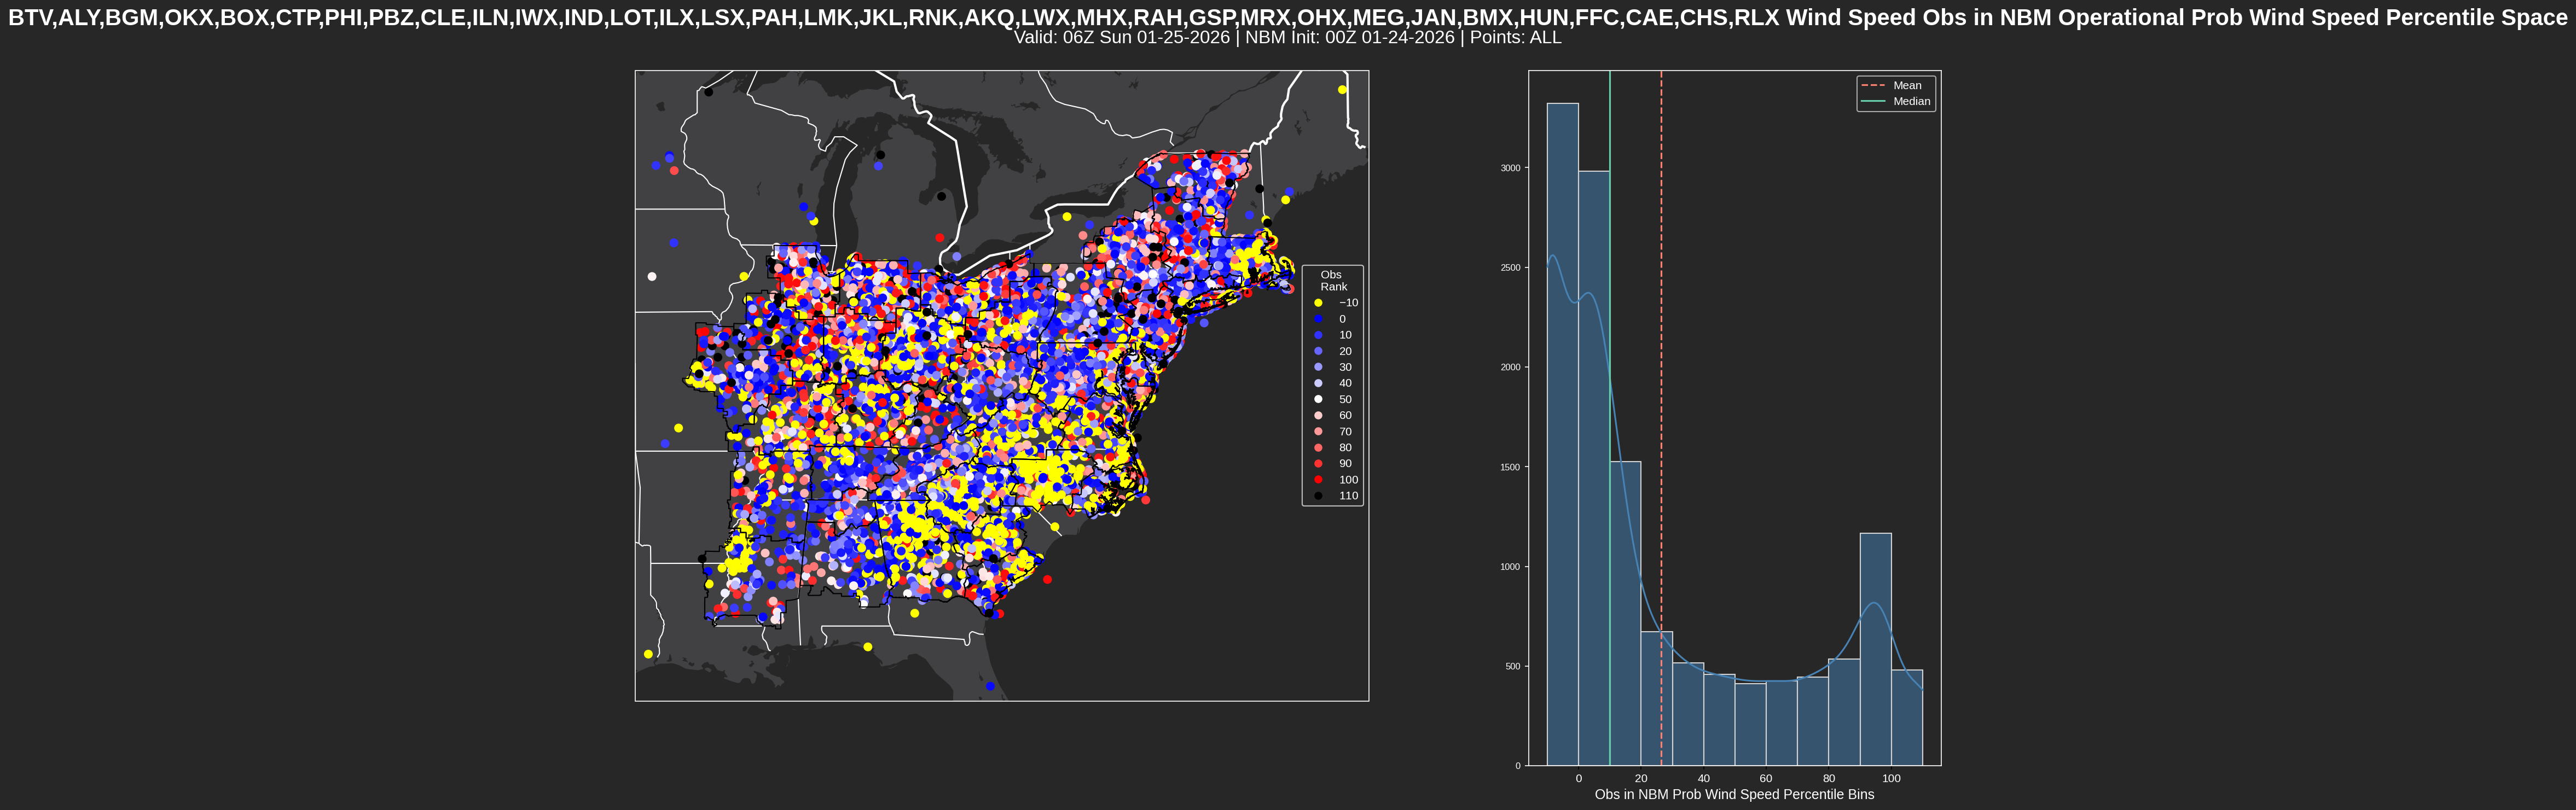

In [20]:
#@title Generate Plot
########################################################################################################################
# Finally, this section makes our plot.                                                                                #
########################################################################################################################

print("Making plot (almost done!)...")
if compare_to =="obs":
  compare_var = "ob_perc"
  compare_element = "Obs"
elif compare_to == "deterministic":
  compare_var = "NBMd_perc"
  if element =="qpf":
    compare_element = "pMean"
  else:
    compare_element = "Detr"

title_dict = {"maxt":["Max T","PMaxT"],"mint":["Min T","PMinT"], "temp":["Temp","PTemp"],"dewp":["DewPt","PDewPt"],"qpf":["QPF","PQPF"], "qpf06":["QPF06","PQPF06"], "qpf12":["QPF12","PQPF12"], "qpf48":["QPF48","PQPF48"],"qpf72":["QPF72","PQPF72"], "maxwind":["Max Wind","Prob Max Wind"], "maxgust":["Max Gust","Prob Max Gust"],"snow":["Snow Acc", "Prob Snow Acc"], "wind":["Wind Speed","Prob Wind Speed"], "gust":["Wind Gust","Prob Wind Gust"]}
matplotlib.rc('axes',facecolor=background_color, edgecolor=text_color)
if "snow" in element or "qpf" in element:
  valid_datetime = valid_date
  fig_valid_date = nbm_qmd_valid_end_datetime.strftime('%Y%m%d_%HZ')
  valid_title = nbm_qmd_valid_end_datetime.strftime('%HZ %a %m-%d-%Y')
elif element in ["wind","gust","temp","dewp"]:
  valid_datetime = nbm_qmd_valid_end_datetime
  fig_valid_date = nbm_qmd_valid_end_datetime.strftime('%Y%m%d_%HZ')
  valid_title = nbm_qmd_valid_end_datetime.strftime('%HZ %a %m-%d-%Y')
else:
  valid_datetime = datetime.strptime(valid_date,'%Y-%m-%d')
  fig_valid_date = valid_datetime.strftime('%Y%m%d')
  valid_title = valid_datetime.strftime('%a %m-%d-%Y')
if (element == "snow"):
  nbm_init_title = core_init.strftime('%HZ %m-%d-%Y')
else:
  nbm_init_title = nbm_init.strftime('%HZ %m-%d-%Y')

def flip(items, ncol):
    return itertools.chain(*[items[i::ncol] for i in range(ncol)])

if region_selection == "CONUS":
  dataframeid = "CONUS"
  #set up multipanel plot
  west =-125.650
  south = 23.377
  east = -66.008
  north = 50.924
  width_ratios = [7,3,3,3]
  lloc = "lower right"
  fig = plt.figure(constrained_layout=True, figsize=(16,9), facecolor=background_color, frameon=True, dpi=150)
  grid = fig.add_gridspec(4,4, width_ratios=width_ratios, hspace=0.2, wspace=0.2, left=0.1, right=0.9)
  fig.text(0.30, 0.885,f'{region_selection} {title_dict[element][0]} {compare_element} in NBM {title_dict[element][1]} Operational Percentile Space',horizontalalignment='center',weight='bold',fontsize=25,color=text_color)
  fig.text(0.30, 0.855,f'Valid: {valid_title}  |  NBM Init: {nbm_init_title}  |  Points: {points_str}',horizontalalignment='center',fontsize=16,color=text_color)

  ax1 = fig.add_subplot(grid[:,:-2], projection=ccrs.Mercator(globe=None))
  ax2 = fig.add_subplot(grid[0,2])
  ax3 = fig.add_subplot(grid[0,3])
  ax4 = fig.add_subplot(grid[1,2])
  ax5 = fig.add_subplot(grid[1,3])
  ax6 = fig.add_subplot(grid[2:,2:])

  conus_df = pd.concat([obs["WR"], obs["CR"], obs["ER"],obs["SR"]])
  lats = conus_df["lat"].values
  lons = conus_df["lon"].values
  point_data = conus_df[compare_var].values
  mean = conus_df[compare_var].mean()
  median = conus_df[compare_var].median()
  mode = conus_df[compare_var].mode().values[0]

  proj = ccrs.PlateCarree()

  ax1.set_anchor('S')
  ax1.set_extent([west, east, south, north], crs=proj)
  #ax1.add_feature(cfeature.LAND, edgecolor='none', facecolor='#414143', zorder=-1)
  ax1.add_feature(cfeature.OCEAN, edgecolor='none', facecolor=map_water_color, zorder=-2)
  ax1.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '50m', edgecolor='none', facecolor=map_land_color, zorder=-1))
  #ax1.add_feature(cfeature.LAKES, edgecolor='none', facecolor='#272727', zorder=0)
  ax1.add_feature(cfeature.NaturalEarthFeature('physical', 'lakes', '10m', edgecolor='none', facecolor=map_water_color, zorder=0))
  ax1.add_feature(cfeature.BORDERS, edgecolor=map_border_color, facecolor='none', linewidth=2, zorder=1)
  #ax1.add_feature(cfeature.NaturalEarthFeature('cultural', 'countries', '50m', edgecolor=map_border_color, facecolor='none', linewidth=2, zorder=2))
  ax1.add_feature(cfeature.NaturalEarthFeature('cultural', 'admin_1_states_provinces_lines', '50m', edgecolor=map_border_color, facecolor='none', linewidth=1, zorder=2))
  #cx.add_basemap(ax1, source='https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Dark_Gray_Base/MapServer/tile/{z}/{y}/{x}', attribution=False)
  scatter = ax1.scatter(lons, lats, c= point_data, cmap=cmap, s=45, transform=proj, vmin=0.0, vmax=100.0)
  #handles, labels = scatter.legend_elements(num=10)
  #legend1 = ax1.legend(flip(handles, 6), flip(labels, 6), ncol=6,loc=lloc, title=f'{compare_element} in NBM Percentile Space', fancybox=True)
  numcols=abs(np.amax(point_data) - np.amin(point_data))//10
  legend1 = ax1.legend(*scatter.legend_elements(num=numcols), loc=lloc, title=f'{compare_element} \n Rank', fancybox=True)
  plt.setp(legend1.get_title(), multialignment='center', color=text_color)
  for text in legend1.get_texts():
    text.set_color(text_color)
  ax1.add_artist(legend1)
  ax1.add_feature(cfeature.NaturalEarthFeature(
    'cultural', 'admin_1_states_provinces_lines', '110m',
    edgecolor='gray', facecolor='none'))
  if cwa_outline:
    try:
      if os.path.exists("shp/w_05mr24.shp"):
        pass
      else:
        cwa_url = "https://www.weather.gov/source/gis/Shapefiles/WSOM/w_05mr24.zip"
        if os.isdir("shp"):
          pass
        else:
          os.mkdir("shp")
        urlretrieve(cwa_url, "shp/nws_cwa_outlines.zip")
      with zipfile.ZipFile("shp/nws_cwa_outlines.zip", 'r') as zip_ref:
          zip_ref.extractall("shp")
          cwa_shapes=gpd.read_file("shp/w_05mr24.shp")
          cwaList=cwa_id.split(',')
          cwa_subset=cwa_shapes[cwa_shapes['WFO'].isin(cwaList)]
          print("Drawing CWA outlines...")
          cwa_feature=ShapelyFeature(cwa_subset.geometry,ccrs.PlateCarree(), edgecolor='black', facecolor='none', linewidth=1, linestyle='-', zorder=4)
          ax1.add_feature(cwa_feature,zorder=4)
    except:
      print("   > Aw shucks, no CWA boundaries for you. Sorry bout that.")
  if county_outline:
    try:
      if os.path.exists("shp/c_08mr23.zip"):
        pass
      else:
        county_url = "https://www.weather.gov/source/gis/Shapefiles/County/c_08mr23.zip"
        if os.isdir("shp"):
          pass
        else:
          os.mkdir("shp")
        urlretrieve(county_url, "shp/counties.zip")
        with zipfile.ZipFile("shp/counties.zip",'r') as zip_ref:
          zip_ref.extractall("shp")
      cty_feature = ShapelyFeature(Reader("shp/c_08mr23.shp").geometries().ccrs.PlateCarree(), edgecolor='white',facecolor='none',linewidth=1.0,linestyle="--",zorder=3)
      ax1.add_feature(cty_feature)
    except:
      print("   > Cannot plot county boundaries.")

  mean_wr = obs["WR"][compare_var].mean()
  median_wr = obs["WR"][compare_var].median()
  #mode_wr = obs["WR"][compare_var].mode().values[0]
  ax2.set_anchor('N')
  sns.histplot(data=obs["WR"], x=compare_var, ax=ax2, kde=True, bins=range(0,110,10),color='steelblue',edgecolor='lightgrey')
  ax2.set_xlabel("Western Region", color=text_color, fontsize=12)
  ax2.axvline(mean_wr, color='salmon', linestyle='--', label="Mean")
  ax2.axvline(median_wr, color='mediumaquamarine', linestyle='-', label="Median")
  #ax2.axvline(mode_wr, color='lightskyblue', linestyle='-', label="Mode")
  ax2.grid(False)
  for tick in ax2.get_xticklabels():
    tick.set_color(text_color)
  for tick in ax2.get_yticklabels():
    tick.set_color(text_color)
  ax2.tick_params(axis='y',labelsize=8, color=text_color)
  legend2 = ax2.legend()
  for text in legend2.get_texts():
    text.set_color(text_color)
  ax2.set(ylabel=None)

  mean_cr = obs["CR"][compare_var].mean()
  median_cr = obs["CR"][compare_var].median()
  #mode_cr = obs["CR"][compare_var].mode().values[0]
  ax3.set_anchor('N')
  sns.histplot(data=obs["CR"], x=compare_var, ax=ax3, kde=True, bins=range(0,110,10),color='steelblue',edgecolor='lightgrey')
  ax3.set_xlabel("Central Region", color=text_color, fontsize=12)
  ax3.axvline(mean_cr, color='salmon', linestyle='--', label="Mean")
  ax3.axvline(median_cr, color='mediumaquamarine', linestyle='-', label="Median")
  #ax3.axvline(mode_cr, color='lightskyblue', linestyle='-', label="Mode")
  ax3.grid(False)
  for tick in ax3.get_xticklabels():
    tick.set_color(text_color)
  for tick in ax3.get_yticklabels():
    tick.set_color(text_color)
  ax3.tick_params(axis='y',labelsize=8, color=text_color)
  legend3 = ax3.legend()
  for text in legend3.get_texts():
    text.set_color(text_color)
  ax3.set(ylabel=None)


  mean_er = obs["ER"][compare_var].mean()
  median_er = obs["ER"][compare_var].median()
  #mode_er = obs["ER"][compare_var].mode().values[0]
  ax4.set_anchor('N')
  sns.histplot(data=obs["ER"], x=compare_var, ax=ax4, kde=True, bins=range(0,110,10),color='steelblue',edgecolor='lightgrey')
  ax4.set_xlabel("Eastern Region", color=text_color, fontsize=12)
  ax4.axvline(mean_er, color='salmon', linestyle='--', label="Mean")
  ax4.axvline(median_er, color='mediumaquamarine', linestyle='-', label="Median")
  #ax4.axvline(mode_er, color='lightskyblue', linestyle='-', label="Mode")
  ax4.grid(False)
  for tick in ax4.get_xticklabels():
    tick.set_color(text_color)
  for tick in ax4.get_yticklabels():
    tick.set_color(text_color)
  ax4.tick_params(axis='y',labelsize=8, color=text_color)
  legend4 = ax4.legend()
  for text in legend4.get_texts():
    text.set_color(text_color)
  ax4.set(ylabel=None)


  mean_sr = obs["SR"][compare_var].mean()
  median_sr = obs["SR"][compare_var].median()
  #mode_sr = obs["SR"][compare_var].mode().values[0]
  ax5.set_anchor('N')
  sns.histplot(data=obs["SR"], x=compare_var, ax=ax5, kde=True, bins=range(0,110,10),color='steelblue',edgecolor='lightgrey')
  ax5.set_xlabel("Southern Region", color=text_color, fontsize=12)
  ax5.axvline(mean_sr, color='salmon', linestyle='--', label="Mean")
  ax5.axvline(median_sr, color='mediumaquamarine', linestyle='-', label="Median")
  #ax5.axvline(mode_sr, color='lightskyblue', linestyle='-', label="Mode")
  ax5.grid(False)
  for tick in ax5.get_xticklabels():
    tick.set_color(text_color)
  for tick in ax5.get_yticklabels():
    tick.set_color(text_color)
  ax5.tick_params(axis='y',labelsize=8, color=text_color)
  legend5 = ax5.legend()
  for text in legend5.get_texts():
    text.set_color(text_color)
  ax5.set(ylabel=None)

  ax6.set_anchor('NC')
  sns.histplot(data=point_data, ax=ax6, kde=True, bins=range(0,110,10),color='steelblue',edgecolor='lightgrey')
  ax6.set_xlabel(f'{compare_element} in NBM {title_dict[element][1]} Percentile Bins', color=text_color, fontsize=12)
  ax6.axvline(mean, color='salmon', linestyle='--', label="Mean")
  ax6.axvline(median, color='mediumaquamarine', linestyle='-', label="Median")
  #ax6.axvline(mode, color='lightskyblue', linestyle='-', label="Mode")
  ax6.grid(False)
  for tick in ax6.get_xticklabels():
    tick.set_color(text_color)
  for tick in ax6.get_yticklabels():
    tick.set_color(text_color)
  ax6.tick_params(axis='y',labelsize=8, color=text_color)
  legend6 = ax6.legend()
  for text in legend6.get_texts():
    text.set_color(text_color)
  ax6.set(ylabel=None)

  #figname=region_selection+"_"+element+"_"+valid_date+".png"
  #plt.savefig(figname, facecolor=fig.get_facecolor(), bbox_inches=None, pad_inches=0.2, dpi='figure')

else:
  #set up two panel plot
  if (region_selection == "WR"):
      west = -126.917
      south = 30.586
      east = -102.740
      north = 49.755
      width, height = (16,9)
      width_ratios = [9,8]
      lloc = "lower right"
  if (region_selection == "CR"):
      west = -111.534
      south = 33.295
      east = -81.723
      north = 49.755
      width, height = (16,7)
      width_ratios = [9,7]
      lloc = "lower center"
  if (region_selection == "ER"):
      west = -86.129
      south = 31.223
      east = -66.465
      north = 47.676
      width, height = (16,7.25)
      width_ratios = [6.9,9.5]
      lloc = "lower right"
  if (region_selection == "SR"):
      west = -109.758
      south = 23.313
      east = -79.247
      north = 36.899
      width, height = (16,5.6)
      width_ratios = [10,6]
      lloc = "lower center"
  if (region_selection == "CWA"):
      west = np.min(filteredObs[region]["lon"]) - 0.5
      south = np.min(filteredObs[region]["lat"]) - 0.5
      east = np.max(filteredObs[region]["lon"]) + 1.0
      north = np.max(filteredObs[region]["lat"]) + 0.5
      width, height = (16,9)
      ratioxy = 16./9.
      width_ratios = [ratioxy, 1]
      lloc = "center right"

  #width, height = (16,9)
  fig = plt.figure(constrained_layout=True, figsize=(width,height), facecolor=background_color, frameon=True, dpi=150)
  if (region_selection == "CWA"):
    dataframeid = cwa_id
  else:
    dataframeid = region_selection
  #ratioxy = 16./9.
  #width_ratios = [ratioxy, 1]
  grid = fig.add_gridspec(1,2, hspace=0.2, width_ratios=width_ratios, height_ratios = [1], wspace=0.2)
  ax1 = fig.add_subplot(grid[0,0], projection=ccrs.Mercator())
  #ax1 = fig.add_subplot(grid[0,0], projection=ccrs.LambertConformal(central_latitude=25, central_longitude=265, standard_parallels=(25,25)))
  ax2 = fig.add_subplot(grid[0,1], )
  fig.text(0.5, 1.05,f'{dataframeid} {title_dict[element][0]} {compare_element} in NBM {verNames[version]} {title_dict[element][1]} Percentile Space',\
           horizontalalignment='center', verticalalignment='bottom', weight='bold',fontsize=20,color=text_color)
  fig.text(0.5, 1.05,f'Valid: {valid_title} | NBM Init: {nbm_init_title} | Points: {points_str}', \
           horizontalalignment='center',verticalalignment='top', fontsize=16,color=text_color)

  lats = filteredObs[dataframeid]["lat"].values
  lons = filteredObs[dataframeid]["lon"].values
  point_data = filteredObs[dataframeid][compare_var].values
  mean = filteredObs[dataframeid][compare_var].mean()
  median = filteredObs[dataframeid][compare_var].median()
  #mode = obs[dataframeid][compare_var].mode().values[0]
  proj = ccrs.PlateCarree()
  numcols=(abs(np.amax(point_data) - np.amin(point_data))//10) + 1

  ax1.set_anchor('N')
  ax1.set_facecolor(background_color)
  ax1.set_extent([west, east, south, north], crs=proj)
  #ax1.add_feature(cfeature.LAND, edgecolor='none', facecolor='#414143', zorder=-1)
  ax1.add_feature(cfeature.OCEAN, edgecolor='none', facecolor=map_water_color, zorder=-2)
  ax1.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '50m', edgecolor='none', facecolor=map_land_color, zorder=-1))
  #ax1.add_feature(cfeature.LAKES, edgecolor='none', facecolor='#272727', zorder=0)
  ax1.add_feature(cfeature.NaturalEarthFeature('physical', 'lakes', '10m', edgecolor='none', facecolor=map_water_color, zorder=0))
  ax1.add_feature(cfeature.BORDERS, edgecolor=map_border_color, facecolor='none', linewidth=2, zorder=2)
  #ax1.add_feature(cfeature.NaturalEarthFeature('cultural', 'countries', '50m', edgecolor=map_border_color, facecolor='none', linewidth=2, zorder=2))
  ax1.add_feature(cfeature.NaturalEarthFeature('cultural', 'admin_1_states_provinces_lines', '50m', edgecolor=map_border_color, facecolor='none', linewidth=1, zorder=2))
  #ax1.add_feature(cfeature.NaturalEarthFeature('cultural', 'admin_1_states_provinces_lines', '50m', edgecolor=map_border, facecolor='none', linewidth=1, zorder=5))
  #cx.add_basemap(ax1, source='https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Dark_Gray_Base/MapServer/tile/{z}/{y}/{x}', attribution=False)
  scatter = ax1.scatter(lons, lats, c= point_data, cmap=cmap, s=45, transform=proj, zorder=2, vmin=0.0, vmax=100.0)

  if region_selection in ("CR","SR"):
    handles, labels = scatter.legend_elements(num=numcols)
    legend1 = ax1.legend(flip(handles, 6), flip(labels, 6), ncol=6,loc=lloc, title=f'{compare_element} in NBM Percentile Space', fancybox=True)
  else:
    legend1 = ax1.legend(*scatter.legend_elements(num=numcols),
                      loc=lloc, title=f'{compare_element} \n Rank', fancybox=True)
  plt.setp(legend1.get_title(), multialignment='center', color=text_color)
  for text in legend1.get_texts():
    text.set_color(text_color)
  ax1.add_artist(legend1)
  #ax1.set(aspect='equal', adjustable='box')
  if cwa_outline:
    try:
      if not os.path.exists("shp/nws_cwa_outlines.zip"):
        cwa_url = "https://www.weather.gov/source/gis/Shapefiles/WSOM/w_18mr25.zip"
        if not os.path.exists("shp"):
          os.mkdir("shp")
        urlretrieve(cwa_url, "shp/nws_cwa_outlines.zip")
      with zipfile.ZipFile("shp/nws_cwa_outlines.zip", 'r') as zip_ref:
        zip_ref.extractall("shp")
        print("  >> Extracted CWA shapefiles")
        cwa_shapes=gpd.read_file("shp/w_18mr25.shp")
        print(" >> Read in shapefiles")
        cwaList=cwa_id.split(',')
        cwaSubset=cwa_shapes[cwa_shapes['CWA'].isin(cwaList)]
        print(">> Drawing CWA Outlines...")
        cwa_feature=ShapelyFeature(cwaSubset.geometry,ccrs.PlateCarree(), edgecolor='black', facecolor='none', linewidth=1.0, linestyle='-', zorder=4)
        #cwa_feature = ShapelyFeature(Reader("shp/w_05mr24.shp").geometries(),ccrs.PlateCarree(), edgecolor='black', facecolor='none', linewidth=1, linestyle='-', zorder=4)
        ax1.add_feature(cwa_feature)
        min_lon, min_lat, max_lon, max_lat = cwaSubset.total_bounds
    except:
      print("Aw shucks, no CWA boundaries for you. Sorry bout that.")
  if county_outline:
    try:
      if os.path.exists("shp/counties.shp"):
        pass
      else:
        county_url = "https://www.weather.gov/source/gis/Shapefiles/County/c_08mr23.zip"
        if os.path.exists("shp"):
          pass
        else:
          os.mkdir("shp")
        urlretrieve(county_url, "shp/counties.zip")
        print("   >> Downloaded county zip file")

      with zipfile.ZipFile("shp/counties.zip",'r') as cty_ref:
        cty_ref.extractall("shp")
        print("   >> Extracted county shape files")
        cty_feature = ShapelyFeature(Reader("shp/c_08mr23.shp").geometries(),ccrs.PlateCarree(), edgecolor='grey', facecolor='none', linewidth=0.5, linestyle=':', zorder=3)
        ax1.add_feature(cty_feature)
    except:
      print("   >> Cannot plot county boundaries.")

  #if region_selection == "SR":
  #ax2.set(aspect=1)
  ax2.set_anchor('C')
  sns.histplot(data=filteredObs[dataframeid], x=compare_var, ax=ax2, kde=True, bins=range(-10,115,10),color='steelblue',edgecolor='lightgrey')
  ax2.set_xlabel(f'{compare_element} in NBM {title_dict[element][1]} Percentile Bins', color=text_color, fontsize=12)
  ax2.axvline(mean, color='salmon', linestyle='--', label="Mean")
  ax2.axvline(median, color='mediumaquamarine', linestyle='-', label="Median")

  ax2.grid(False)
  for tick in ax2.get_xticklabels():
    tick.set_color(text_color)
  for tick in ax2.get_yticklabels():
    tick.set_color(text_color)
  ax2.tick_params(axis='y',labelsize=8, color=text_color)
  legend2 = ax2.legend()
  for text in legend2.get_texts():
    text.set_color(text_color)
  ax2.set(ylabel=None)


#figname="map_"+dataframeid+"_"+compare_element+"_"+element+"_"+nbm_init.strftime('%Y%m%d')+"_"+valid_end_datetime.strftime('%Y%m%d')+".png"
figname=f"map_{dataframeid}_{compare_element}_{element}_{nbm_init.strftime('%Y%m%d')}_{valid_end_datetime.strftime('%Y%m%d')}_{version}.png"
plt.savefig(figname, facecolor=fig.get_facecolor(), bbox_inches='tight', pad_inches=0.2, dpi='figure')
print(f'   > Done! Saved plot as {figname}')